In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path
from galaxy_sidm.io import load_config, load_flat
from galaxy_sidm.data.aida_tng import base_path
from galaxy_sidm.mock import disc_coords, disc_velocities, load_galaxy_gas, vcirc_at
from galaxy_sidm.mock.tables import DISC_RULE, MODELS, calibration_classes, residual_asymmetry_sample, gas_disc_sample, kinematic_sample
import random
import json
import pandas as pd

plt.rcParams.update({
    # paper font: bundled Computer Modern (cmr10) -- do NOT use usetex here
    "font.family": "serif",
    "font.serif": ["cmr10", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "axes.formatter.use_mathtext": True,
    "axes.unicode_minus": False,
    # legibility
    "axes.labelsize": 19,
    "axes.titlesize": 19,
    "xtick.labelsize": 15,
    "ytick.labelsize": 15,
    "legend.fontsize": 14,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.top": True, "ytick.right": True,
    "xtick.major.size": 5.5, "ytick.major.size": 5.5,
})

cfg = load_config(None)
PROC = Path(cfg["paths"]["scratch_processed"])
MORDOR = Path(cfg["paths"]["scratch_mordor"]) / "samples"
h = float(cfg["cosmology"]["h"])
colors = cfg["model_colors"]
class_colors = {"discs": "tab:green", "unsure_discs": "tab:orange", "perturbed": "tab:red"}
kappa_cut = 0.8
z_show = 0.5
n_show = 1
thresholds = [0.7, 0.8]
watch = [("vSIDM", 0.5, 53007)]
n_disagree = 3
LISTS = Path.home() / "tmp"

In [2]:
data = {}
for model in MODELS:
    for snap, z in sorted((int(s), float(z)) for s, z in cfg["snap_z"].items()):
        mordor = MORDOR / f"mordor_sample_{model}_{snap:03d}.hdf5"
        if not mordor.exists():
            continue
        a, _ = load_flat(PROC / "gas_kinematics" / f"gas_kinematics_{model}_{snap:03d}.hdf5")
        s, _ = load_flat(mordor)
        row = {int(sub): k for k, sub in enumerate(s["halo_ids"])}
        idx = [row[int(sub)] for sub in a["halo_ids"]]
        a["sat_mass_ratio"], a["sat_r_sep"], a["snap"] = s["sat_mass_ratio"][idx], s["sat_r_sep"][idx], snap
        data[(model, z)] = a
redshifts = sorted({z for _, z in data})
print("galaxies at z =", redshifts)
for model in MODELS:
    print(f"{model:6s}", [len(data[(model, z)]["halo_ids"]) if (model, z) in data else "-" for z in redshifts])

galaxies at z = [0.0, 0.5, 1.0, 2.0, 3.0, 4.0, 5.0]
CDM    [443, 460, 425, 259, 122, 23, 1]
SIDM1  ['-', 503, 477, 312, 139, 33, 4]
vSIDM  [438, 461, 437, 283, 116, 24, 3]


CDM z = 0: 87% of 443 have kappa_co >= 0.8
vSIDM z = 0: 88% of 438 have kappa_co >= 0.8
CDM z = 0.5: 87% of 460 have kappa_co >= 0.8
SIDM1 z = 0.5: 84% of 503 have kappa_co >= 0.8
vSIDM z = 0.5: 83% of 461 have kappa_co >= 0.8
CDM z = 1: 76% of 425 have kappa_co >= 0.8
SIDM1 z = 1: 80% of 477 have kappa_co >= 0.8
vSIDM z = 1: 77% of 437 have kappa_co >= 0.8
CDM z = 2: 62% of 259 have kappa_co >= 0.8
SIDM1 z = 2: 60% of 312 have kappa_co >= 0.8
vSIDM z = 2: 55% of 283 have kappa_co >= 0.8
CDM z = 3: 40% of 122 have kappa_co >= 0.8
SIDM1 z = 3: 42% of 139 have kappa_co >= 0.8
vSIDM z = 3: 41% of 116 have kappa_co >= 0.8
CDM z = 4: 48% of 23 have kappa_co >= 0.8
SIDM1 z = 4: 30% of 33 have kappa_co >= 0.8
vSIDM z = 4: 25% of 24 have kappa_co >= 0.8
CDM z = 5: 0% of 1 have kappa_co >= 0.8
SIDM1 z = 5: 50% of 4 have kappa_co >= 0.8
vSIDM z = 5: 0% of 3 have kappa_co >= 0.8


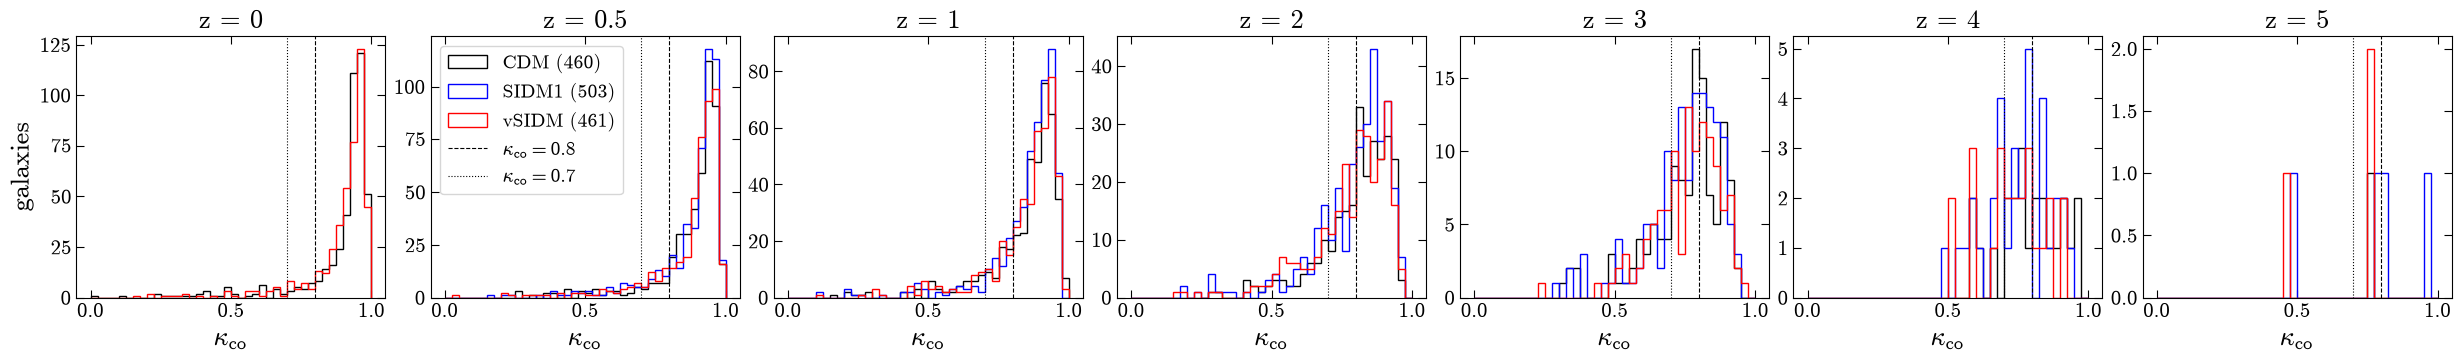

In [3]:
bins = np.linspace(0, 1, 41)
fig, axes = plt.subplots(1, len(redshifts), figsize=(3.5 * len(redshifts), 3.5), sharex=True, constrained_layout=True)
for ax, z in zip(axes, redshifts):
    for model in MODELS:
        if (model, z) not in data:
            continue
        k = data[(model, z)]["kappa_co_r99"]
        ax.hist(k, bins=bins, histtype="step", color=colors[model], label=f"{model} ({len(k)})")
        print(f"{model} z = {z:g}: {np.mean(k >= kappa_cut):.0%} of {len(k)} have kappa_co >= {kappa_cut}")
    ax.axvline(kappa_cut, color="k", ls="--", lw=0.8, label=r"$\kappa_{\rm co} = 0.8$")
    ax.axvline(0.7, color="k", ls=":", lw=0.8, label=r"$\kappa_{\rm co} = 0.7$")
    ax.set_title(f"z = {z:g}")
    ax.set_xlabel(r"$\kappa_{\rm co}$")
axes[1].legend()
axes[0].set_ylabel("galaxies")
plt.show()

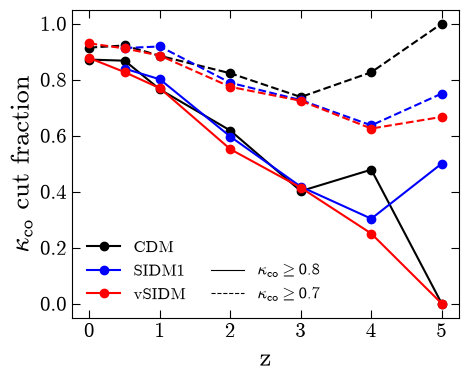

In [4]:
#plot percentage of galaxies with kappa_co >= 0.8 as a function of redshift for each model
plt.figure(figsize=(5, 4))
for model in MODELS:
    perc = []
    perc_07 = []
    for z in redshifts:
        if (model, z) not in data:
            perc.append(np.nan)
            perc_07.append(np.nan)
            continue
        k = data[(model, z)]["kappa_co_r99"]
        perc.append(np.mean(k >= kappa_cut))
        perc_07.append(np.mean(k >= 0.7))
    plt.plot(redshifts, perc, marker="o", color=colors[model], label=model)
    plt.plot(redshifts, perc_07, marker="o", color=colors[model], ls="--")
plt.xlabel("z")
plt.ylabel(rf"$\kappa_{{\rm co}}$ cut fraction")
plt.legend(frameon=False, fontsize=12)
ax = plt.gca()
legend = ax.get_legend()
if legend is not None:
    ax.add_artist(legend)
custom_lines = [Line2D([0], [0], color="k", ls="-", lw=0.8),
                Line2D([0], [0], color="k", ls="--", lw=0.8)]
plt.legend(custom_lines, [r"$\kappa_{\rm co} \geq 0.8$", r"$\kappa_{\rm co} \geq 0.7$"], frameon=False, loc="lower center", fontsize=12)
plt.show()

/home2/s4636708/venvs/thesis/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/home2/s4636708/venvs/thesis/lib/python3.11/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


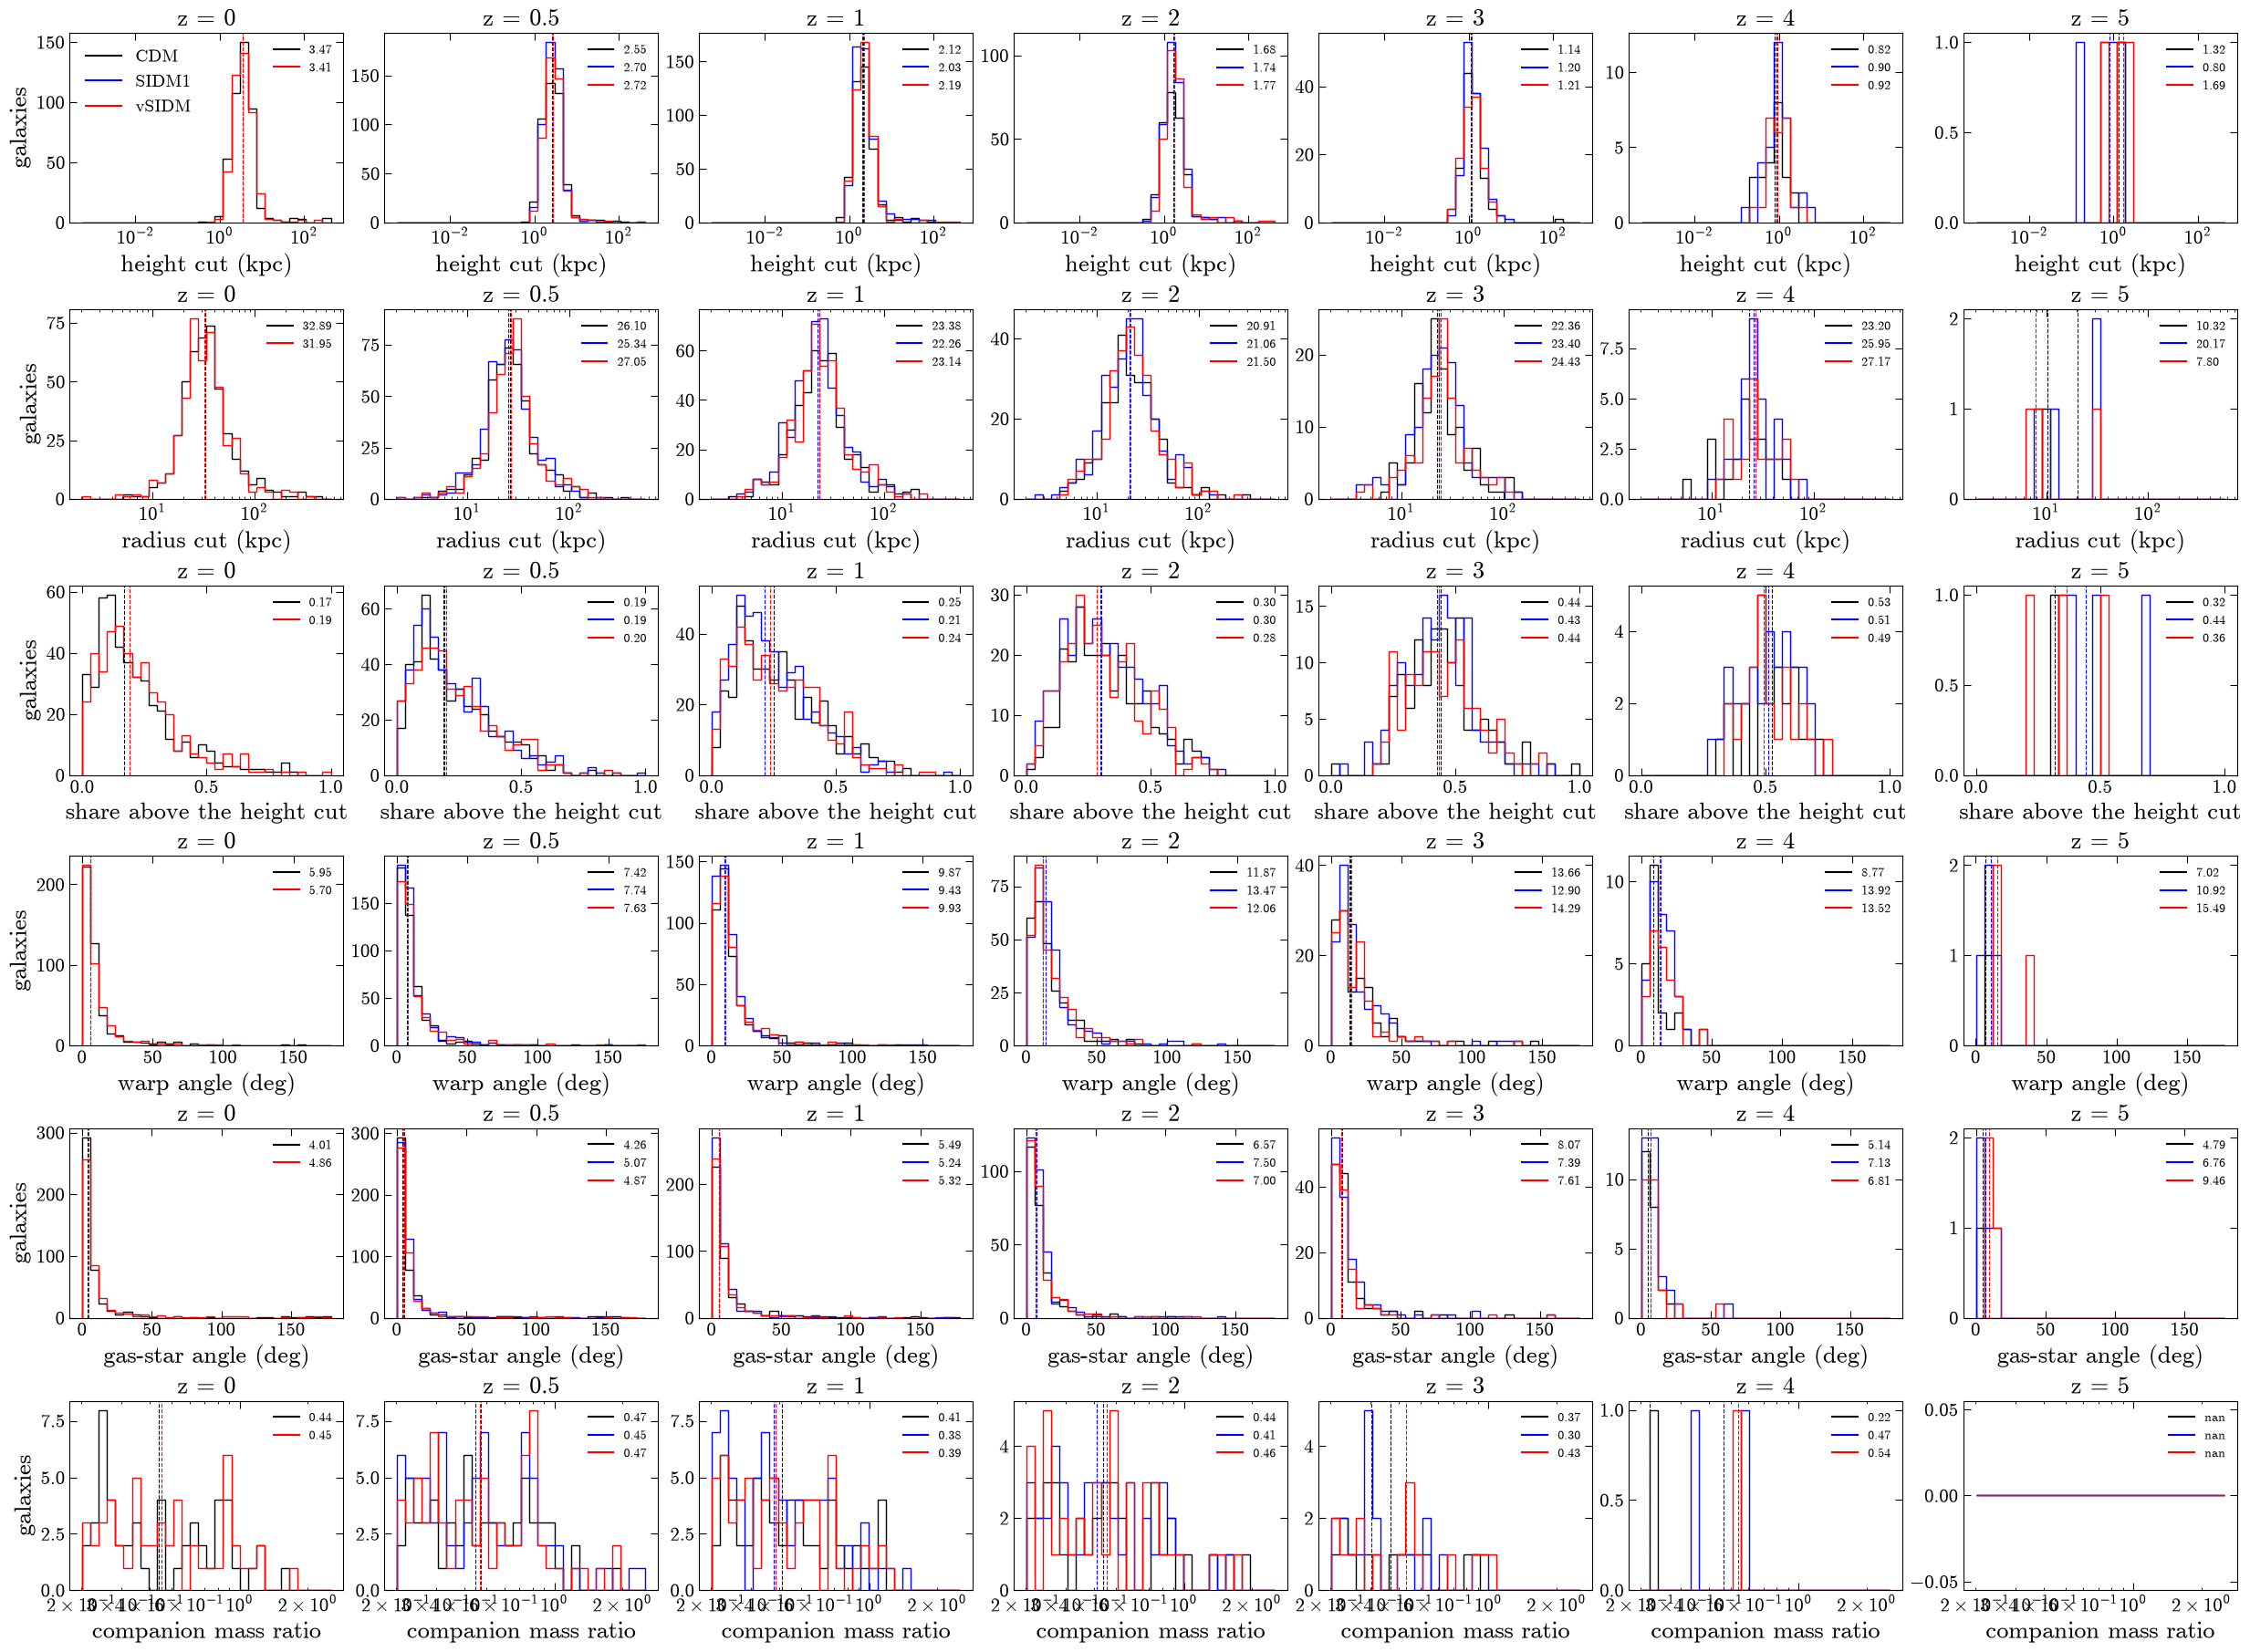

CDM    without a companion: [392, 397, 367, 225, 109, 22, 1]
SIDM1  without a companion: ['-', 422, 400, 270, 119, 31, 4]
vSIDM  without a companion: [387, 389, 375, 243, 100, 23, 3]


In [5]:
diagnostics = {"z_cut": "height cut (kpc)", "R_cut": "radius cut (kpc)",
               "f_above_zcut": "share above the height cut", "warp_deg": "warp angle (deg)",
               "gas_star_deg": "gas-star angle (deg)", "sat_mass_ratio": "companion mass ratio"}
log_scale = {"z_cut", "R_cut", "sat_mass_ratio"}
fig, axes = plt.subplots(len(diagnostics), len(redshifts), figsize=(3.5 * len(redshifts), 3 * len(diagnostics)), constrained_layout=True)
for row, (key, label) in zip(axes, diagnostics.items()):
    vals = {k: a[key][np.isfinite(a[key]) & ((a[key] > 0) | (key not in log_scale))] for k, a in data.items()}
    allv = np.concatenate(list(vals.values()))
    if key in log_scale:
        bins = np.logspace(np.log10(allv.min()), np.log10(allv.max()), 31)
    else:
        bins = np.linspace(allv.min(), allv.max(), 31)
    for ax, z in zip(row, redshifts):
        labels = []
        for model in MODELS:
            if (model, z) in vals:
                ax.hist(vals[(model, z)], bins=bins, histtype="step", color=colors[model])
                ax.axvline(np.median(vals[(model, z)]), color=colors[model], ls="--", lw=0.8)
                labels.append(f"{np.median(vals[(model, z)]):.2f}")
        if key in log_scale:
            ax.set_xscale("log")
        ax.set_title(f"z = {z:g}")
        ax.set_xlabel(label)
        handles = [plt.Line2D([0], [0], color=colors[model]) for model in MODELS if (model, z) in vals]
        ax.legend(handles=handles, labels=labels, frameon=False, fontsize=10)
    row[0].set_ylabel("galaxies")
axes[0, 0].add_artist(axes[0, 0].get_legend())
axes[0, 0].legend([plt.Line2D([0], [0], color=colors[model]) for model in MODELS], MODELS,
                  frameon=False, loc="upper left")
plt.show()
for model in MODELS:
    print(f"{model:6s} without a companion:", [int((data[(model, z)]["sat_mass_ratio"] == 0).sum()) if (model, z) in data else "-" for z in redshifts])

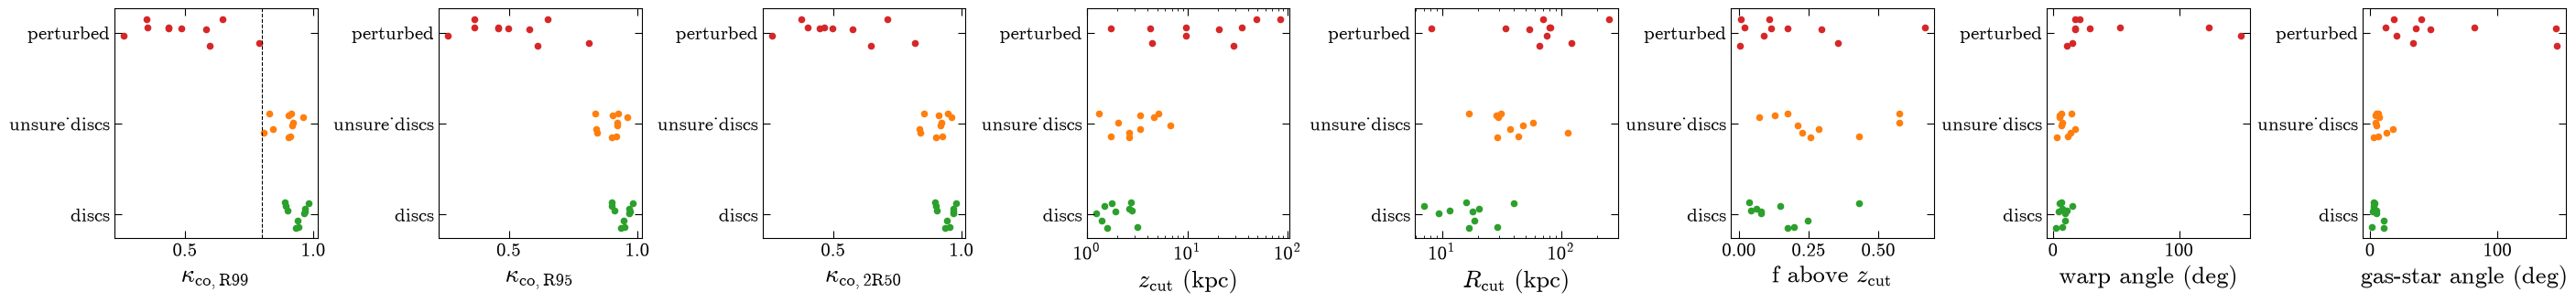

In [6]:
cls_of = calibration_classes()
classes = list(class_colors)
quantities = ["kappa_co_r99", "kappa_co_r95", "kappa_co_2rhalf", "z_cut", "R_cut", "f_above_zcut", "warp_deg", "gas_star_deg"]
titles = [r"$\kappa_{\rm co, R99}$", r"$\kappa_{\rm co, R95}$", r"$\kappa_{\rm co, 2R50}$", r"$z_{\rm cut}$ (kpc)", r"$R_{\rm cut}$ (kpc)", r"f above $z_{\rm cut}$", "warp angle (deg)", "gas-star angle (deg)"]
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, len(quantities), figsize=(3.5 * len(quantities), 3.2), constrained_layout=True)
for (model, z, sub), c in cls_of.items():
    a = data[(model, z)]
    i = np.flatnonzero(a["halo_ids"] == sub)
    if len(i) != 1:
        print(f"{model} z = {z:g} {sub} ({c}): not in the gas-kinematics file")
        continue
    y = classes.index(c) + rng.uniform(-0.15, 0.15)
    for ax, q in zip(axes, quantities):
        ax.scatter(a[q][i[0]], y, color=class_colors[c], s=20)
for ax, q in zip(axes, quantities):
    if q in log_scale:
        ax.set_xscale("log")
    ax.set_yticks(range(len(classes)), classes)
    ax.set_xlabel(titles[quantities.index(q)])
axes[0].axvline(kappa_cut, color="k", ls="--", lw=0.8)
plt.show()

In [7]:
def plot_galaxies(galaxies):
    """Face-on map of v_phi / v_circ and the ring profiles, one row per (model, z, subID)."""
    fig, axes = plt.subplots(len(galaxies), 2, figsize=(10, 4.5 * len(galaxies)), constrained_layout=True, squeeze=False)
    for row, (model, z, sub) in zip(axes, galaxies):
        a = data[(model, z)]
        i = np.flatnonzero(a["halo_ids"] == sub)
        if len(i) != 1:
            raise KeyError(f"{model} z = {z:g} {sub} is not in the gas-kinematics file")
        i = i[0]
        zhat = a["zhat"][i]
        vc, _ = load_flat(PROC / "vcirc" / f"vcirc_{model}_{a['snap']:03d}.hdf5")
        j = np.flatnonzero(vc["halo_ids"] == sub)[0]
        gas = load_galaxy_gas(base_path(cfg, model), a["snap"], sub, h=h)
        xyz = gas.xyz_g.to_value("kpc")
        height, R = disc_coords(xyz, zhat)
        keep = (np.abs(height) < a["z_cut"][i]) & (R < a["R_cut"][i])
        m = gas.mH_neutral_g.to_value("Msun")[keep]
        _, v_phi, _ = disc_velocities(xyz[keep], gas.vxyz_g.to_value("km/s")[keep] - a["v_bulk"][i], zhat)
        ratio = v_phi / vcirc_at(R[keep], vc["R_direct"][j], vc["vcirc_total"][j])
        e1 = np.cross(zhat, [0, 0, 1] if abs(zhat[2]) < 0.9 else [1, 0, 0])
        e1 /= np.linalg.norm(e1)
        e2 = np.cross(zhat, e1)
        cum = np.cumsum(a["ring_mass"][i]) / a["ring_mass"][i].sum()
        R_show = a["ring_edges"][1:][np.searchsorted(cum, 0.95)]
        bins = np.linspace(-R_show, R_show, 61)
        ok = np.isfinite(ratio)
        X, Y = xyz[keep][ok] @ e1, xyz[keep][ok] @ e2
        num = np.histogram2d(X, Y, bins=[bins, bins], weights=(m * ratio)[ok])[0]
        den = np.histogram2d(X, Y, bins=[bins, bins], weights=m[ok])[0]
        with np.errstate(invalid="ignore"):
            im = row[0].pcolormesh(bins, bins, (num / den).T, cmap="RdBu", vmin=0, vmax=2)
        fig.colorbar(im, ax=row[0], label=r"$v_\phi / v_{\rm circ}$, mass-weighted")
        row[0].set_aspect("equal")
        row[0].set_title(rf"{model} z = {z:g} {sub}: $\kappa_{{\rm co}}$ = {a['kappa_co_r99'][i]:.2f}")
        row[0].set_xlabel("x in the disc plane (kpc)")
        row[0].set_ylabel("y in the disc plane (kpc)")
        Rc = 0.5 * (a["ring_edges"][1:] + a["ring_edges"][:-1])
        s = Rc <= R_show
        row[1].plot(Rc[s], a["ring_vphi"][i][s], color="k", label=r"$v_\phi$")
        row[1].fill_between(Rc[s], (a["ring_vphi"][i] - a["ring_sigma_vphi"][i])[s],
                            (a["ring_vphi"][i] + a["ring_sigma_vphi"][i])[s], color="k", alpha=0.2, lw=0)
        row[1].plot(Rc[s], a["ring_vcirc"][i][s], color="k", ls="--", label=r"$v_{\rm circ}$")
        row[1].plot(Rc[s], a["ring_vR"][i][s], color="tab:blue", label=r"$v_R$")
        row[1].plot(Rc[s], a["ring_vz"][i][s], color="tab:orange", label=r"$v_z$")
        row[1].set_xlabel("R (kpc)")
        row[1].set_ylabel("km/s")
        row[1].legend(fontsize=8)
    plt.show()

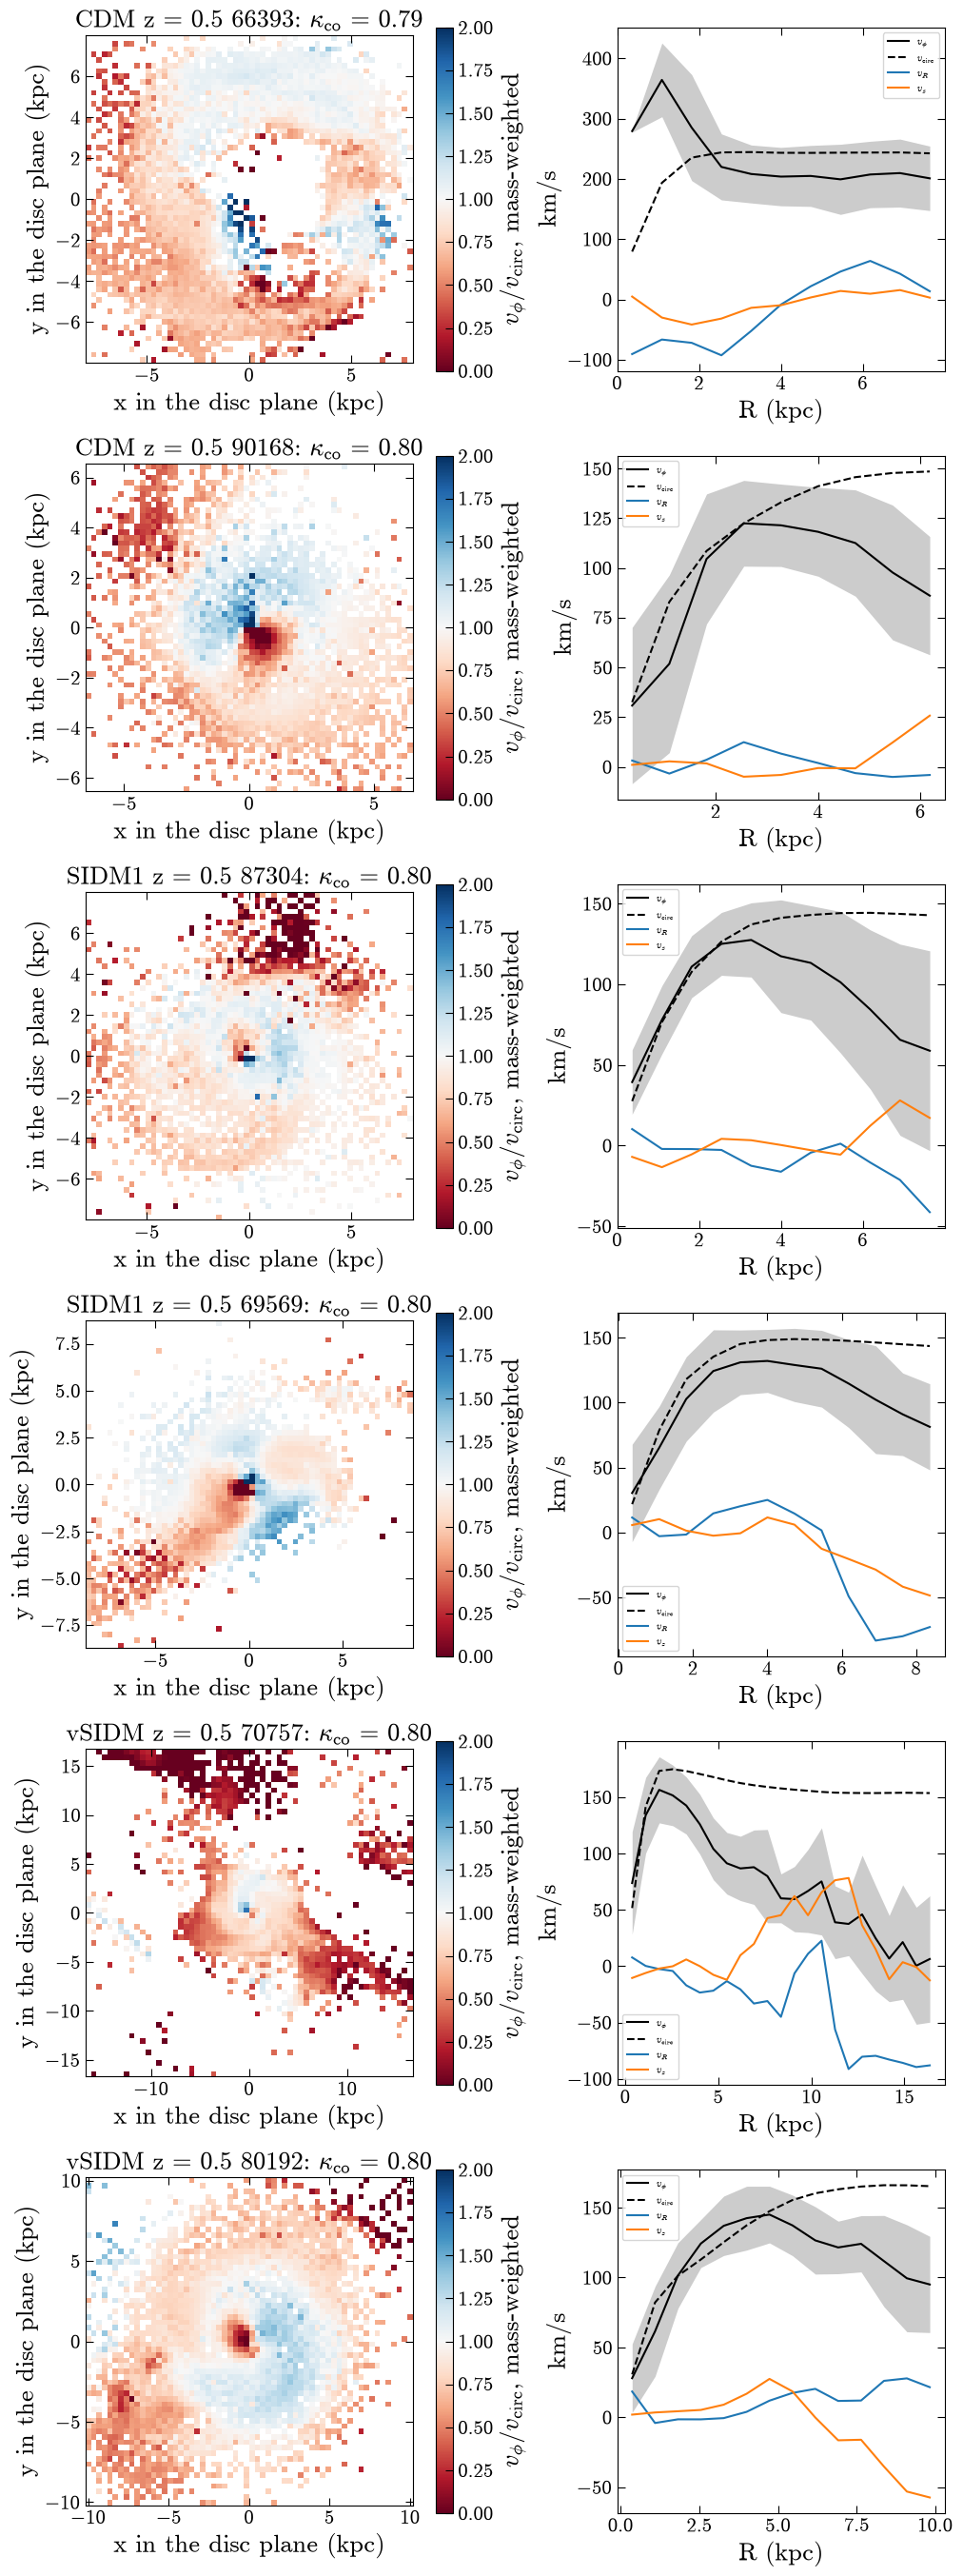

In [8]:
examples = []
for model in MODELS:
    if (model, z_show) not in data:
        print(f"{model} z = {z_show:g}: no galaxies")
        continue
    a = data[(model, z_show)]
    k = a["kappa_co_r99"]
    below, above = np.flatnonzero(k < kappa_cut), np.flatnonzero(k >= kappa_cut)
    examples += [(model, z_show, int(a["halo_ids"][i])) for i in below[np.argsort(kappa_cut - k[below])][:n_show]]
    examples += [(model, z_show, int(a["halo_ids"][i])) for i in above[np.argsort(k[above] - kappa_cut)][:n_show]]
plot_galaxies(examples)

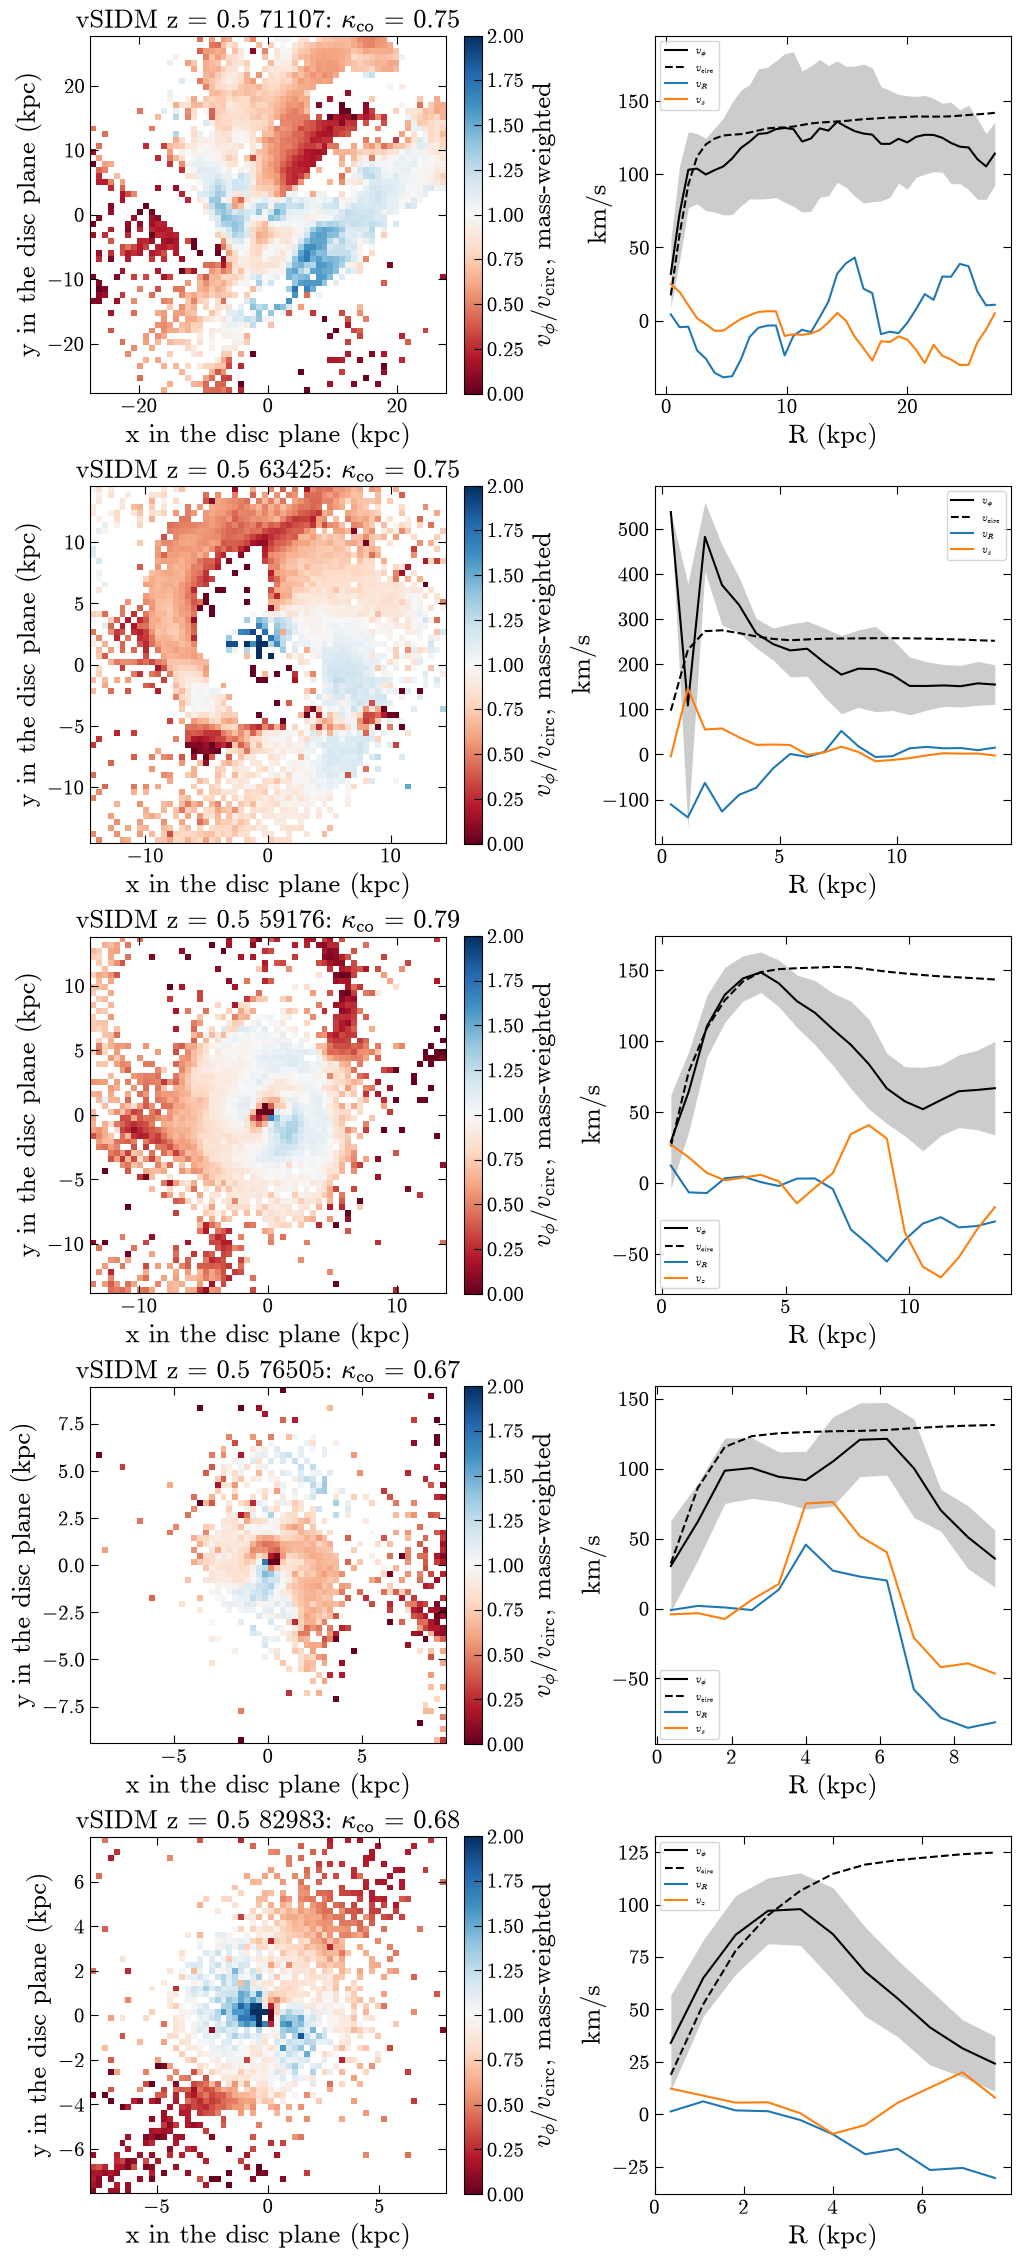

In [9]:
for model in MODELS:
    if (model, z_show) not in data:
        print(f"{model} z = {z_show:g}: no galaxies")
        continue
    a = data[(model, z_show)]
    k = a["kappa_co_r95"]
    above = np.flatnonzero((k >= 0.7) & (k < 0.8))
    below = np.flatnonzero(k < 0.5)
    examples_high = random.sample([(model, z_show, int(a["halo_ids"][i])) for i in above[np.argsort(k[above])]], k=5)
    examples_low = random.sample([(model, z_show, int(a["halo_ids"][i])) for i in below[np.argsort(k[below])]], k=5)
plot_galaxies(examples_high)
# plot_galaxies(examples_low)

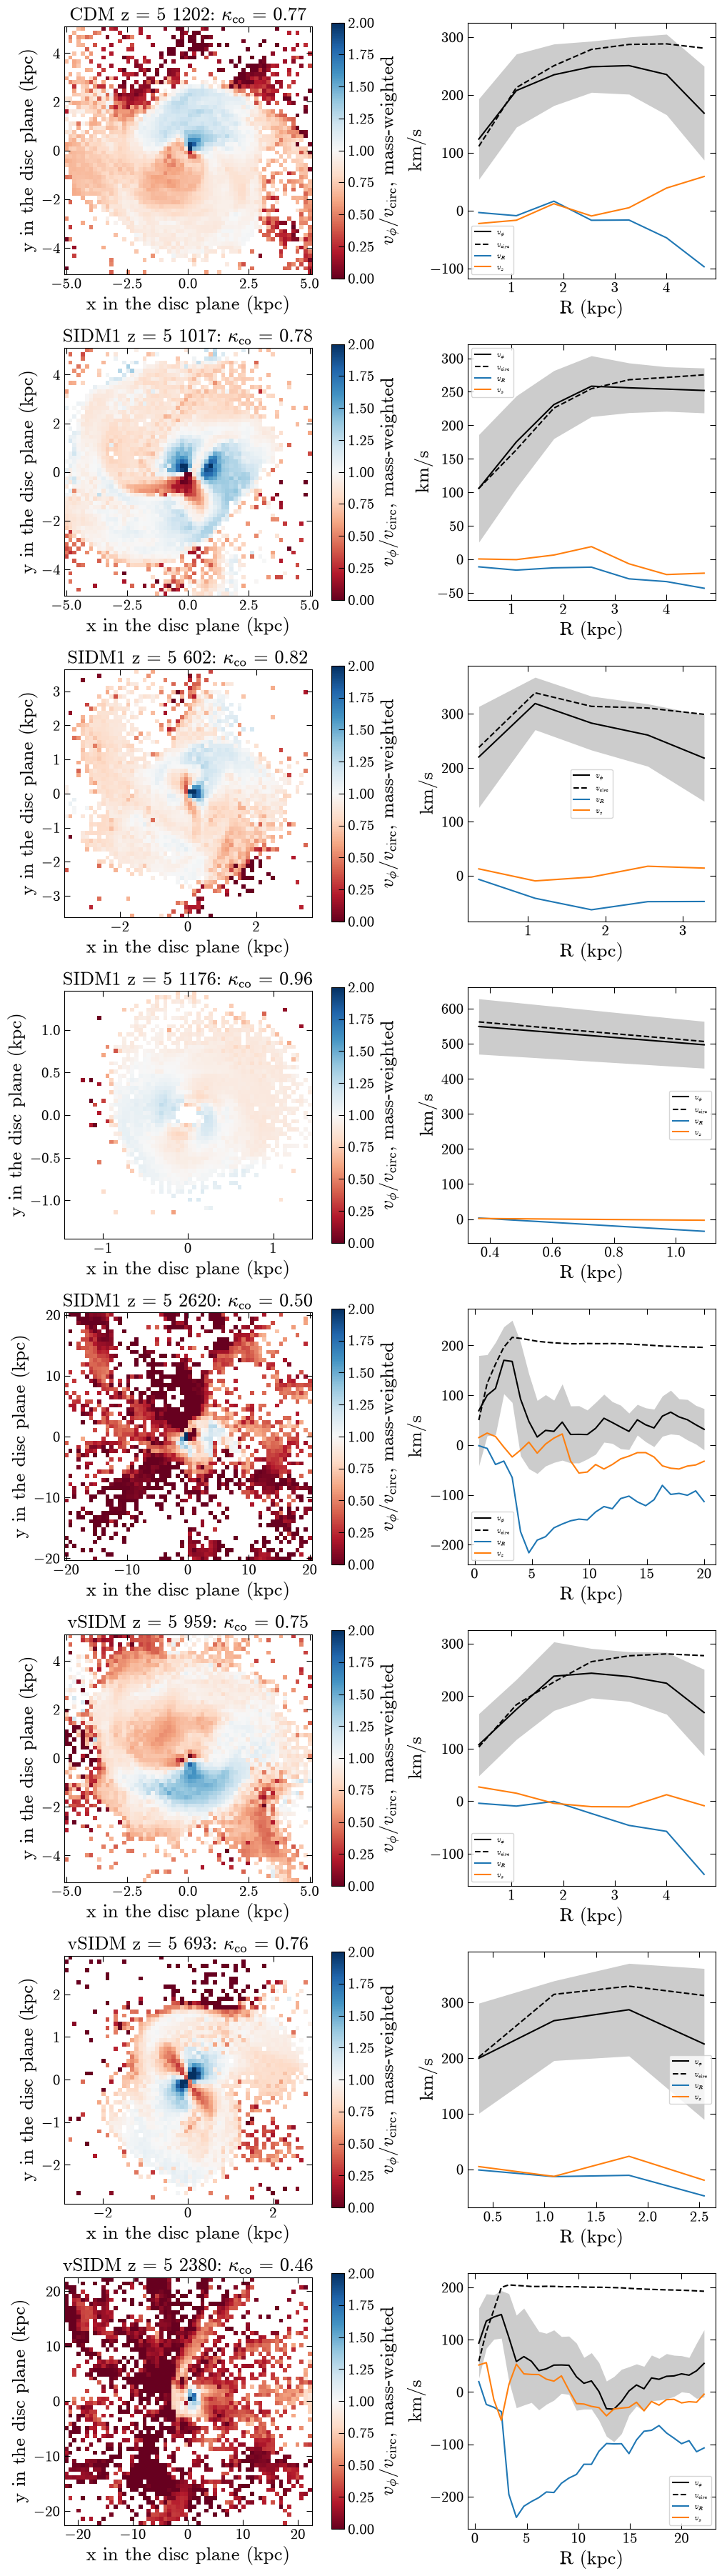

In [10]:
#show the z5 galaxies with plot_galaxies
galaxies_z5 = [
    (model, 5.0, int(sub))
    for model in MODELS
    if (model, 5.0) in data
    for sub in data[(model, 5.0)]["halo_ids"]
]

plot_galaxies(galaxies_z5)

---

In [11]:
gd = gas_disc_sample(cfg)
old, old_line = residual_asymmetry_sample(cfg)
print("old selection:", old_line)
in_old = {(m, s, sub) for (m, s), subs in old.items() for sub in subs}
in_new = {t: {(m, s, sub) for (m, s), subs in kinematic_sample(cfg, t)[0].items() for sub in subs} for t in thresholds}
quantities = ["kappa_co_r99", "kappa_co_r95", "kappa_co_2rhalf", "R_95", "R_half_gas", "z_cut", "R_cut",
              "f_above_zcut", "warp_deg", "gas_star_deg", "sat_mass_ratio"]
kin = pd.concat([pd.DataFrame({"model": model, "z": z, "snap": a["snap"], "subID": a["halo_ids"].astype(int),
                               **{q: a[q] for q in quantities}}) for (model, z), a in data.items()], ignore_index=True)
df = kin.merge(gd[["model", "z", "subID", "A_sq", "mix", "perturbed", "flagged", "in_sample"]], on=["model", "z", "subID"])
left_out = kin.merge(df[["model", "z", "subID"]], how="left", indicator=True).query("_merge == 'left_only'")
print("galaxies without an old classification (no mock fits), per z:", left_out.groupby("z").size().to_dict())
df["old_class"] = np.select([df["in_sample"], df["perturbed"], df["flagged"]], ["disc", "perturbed", "flagged"], "not placed")
keys = list(zip(df["model"], df["snap"], df["subID"]))
df["old_disc"] = [k in in_old for k in keys]
for t in thresholds:
    df[f"new_{t:g}"] = [k in in_new[t] for k in keys]

old selection: res2 mix = 13.579 + -14.267 A_sq, mix = 0.295 PV + 0.705 cube res2
galaxies without an old classification (no mock fits), per z: {0.0: 881}


In [12]:
rows = []
for (model, z), g in df.groupby(["model", "z"]):
    for t in thresholds:
        new = g[f"new_{t:g}"]
        rows.append(dict(model=model, z=z, kappa_min=t, galaxies=len(g), old=int(g["old_disc"].sum()), new=int(new.sum()),
                         both=int((g["old_disc"] & new).sum()), only_old=int((g["old_disc"] & ~new).sum()),
                         only_new=int((~g["old_disc"] & new).sum()), neither=int((~g["old_disc"] & ~new).sum())))
counts = pd.DataFrame(rows)
counts["agree"] = (counts["both"] + counts["neither"]) / counts["galaxies"]
counts

,model,z,kappa_min,galaxies,old,new,both,only_old,only_new,neither,agree
0,CDM,0.5,0.7,460,439,424,417,22,7,14,0.936957
1,CDM,0.5,0.8,460,439,399,394,45,5,16,0.891304
2,CDM,1.0,0.7,425,402,376,371,31,5,18,0.915294
3,CDM,1.0,0.8,425,402,325,323,79,2,21,0.809412
4,CDM,2.0,0.7,259,242,213,210,32,3,14,0.864865
5,CDM,2.0,0.8,259,242,160,160,82,0,17,0.683398
6,CDM,3.0,0.7,122,114,90,87,27,3,5,0.754098
7,CDM,3.0,0.8,122,114,49,48,66,1,7,0.450820
8,CDM,4.0,0.7,23,22,19,19,3,0,1,0.869565
9,CDM,4.0,0.8,23,22,11,11,11,0,1,0.521739


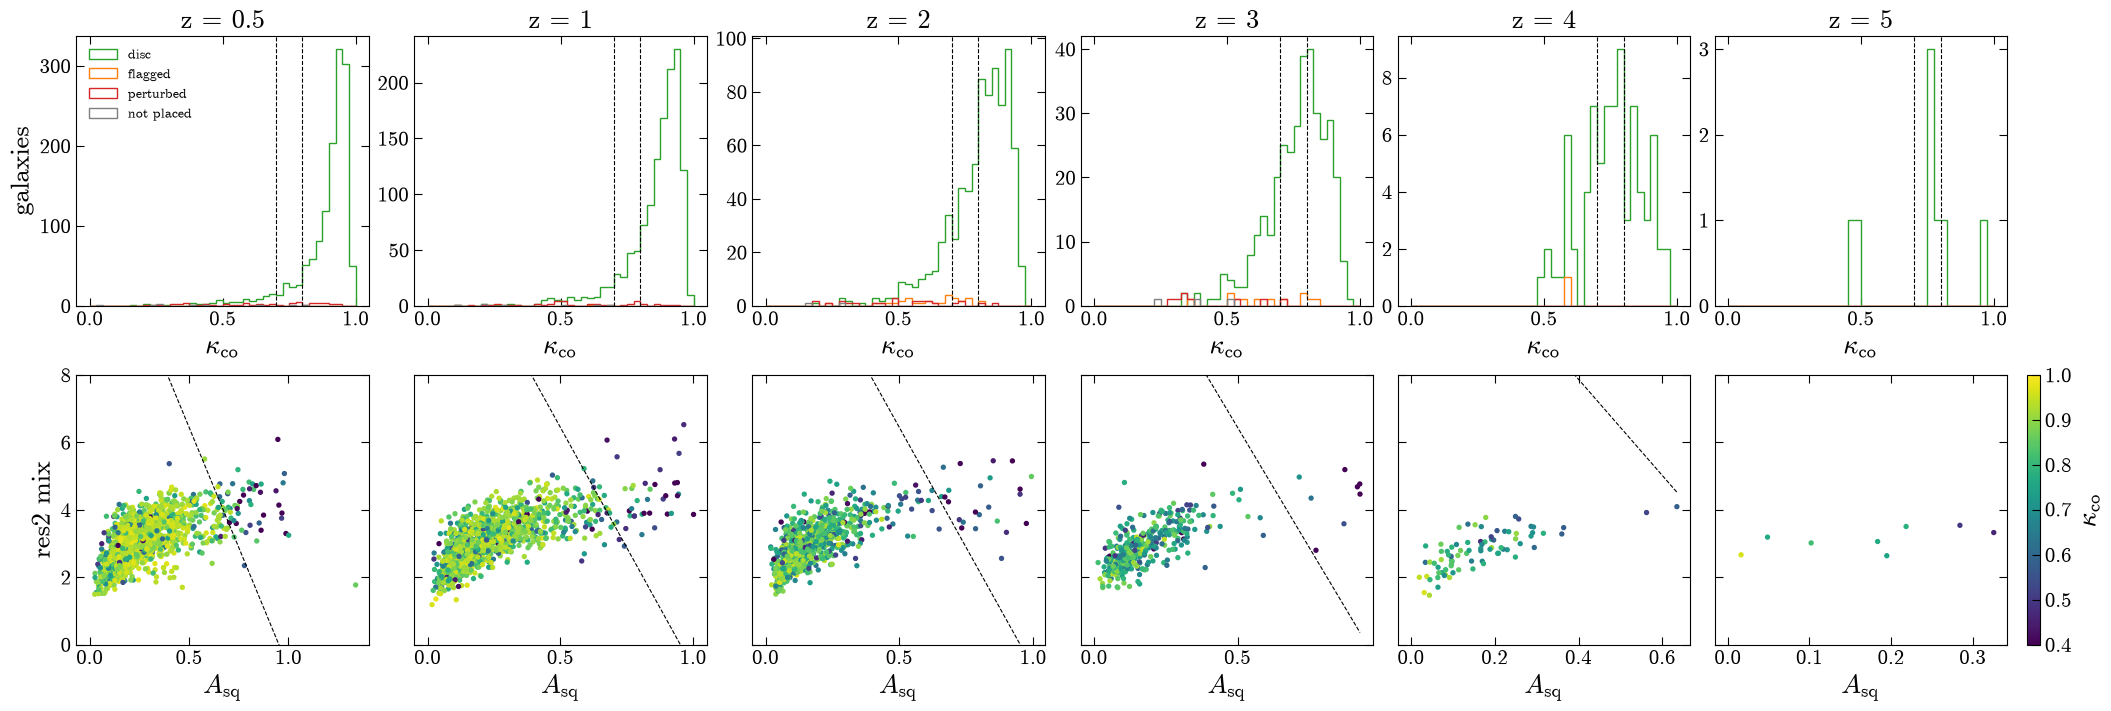

In [13]:
zs = sorted(df["z"].unique())
old_colors = {"disc": "tab:green", "flagged": "tab:orange", "perturbed": "tab:red", "not placed": "tab:gray"}
bins = np.linspace(0, 1, 41)
fig, axes = plt.subplots(2, len(zs), figsize=(3.5 * len(zs), 7), constrained_layout=True)
for col, z in zip(axes.T, zs):
    g = df[df["z"] == z]
    for c, color in old_colors.items():
        col[0].hist(g.loc[g["old_class"] == c, "kappa_co_r99"], bins=bins, histtype="step", color=color, label=c)
    for t in thresholds:
        col[0].axvline(t, color="k", ls="--", lw=0.8)
    col[0].set_title(f"z = {z:g}")
    col[0].set_xlabel(r"$\kappa_{\rm co}$")
    sc = col[1].scatter(g["A_sq"], g["mix"], c=g["kappa_co_r99"], s=8, cmap="viridis", vmin=0.4, vmax=1)
    a_sq = np.linspace(0, np.nanmax(g["A_sq"]), 10)
    col[1].plot(a_sq, gd.attrs["line_intercept"] + gd.attrs["line_slope"] * a_sq, color="k", ls="--", lw=0.8)
    col[1].set_xlabel(r"$A_{\rm sq}$")
axes[0, 0].set_ylabel("galaxies")
axes[1, 0].set_ylabel("res2 mix")
axes[1, 0].set_ylim(0, 8)
for ax in axes[1, 1:]:
    ax.sharey(axes[1, 0])
    ax.tick_params(labelleft=False)
axes[0, 0].legend(fontsize=10, frameon=False)
fig.colorbar(sc, ax=axes[1], label=r"$\kappa_{\rm co}$", pad=0.01)
plt.show()

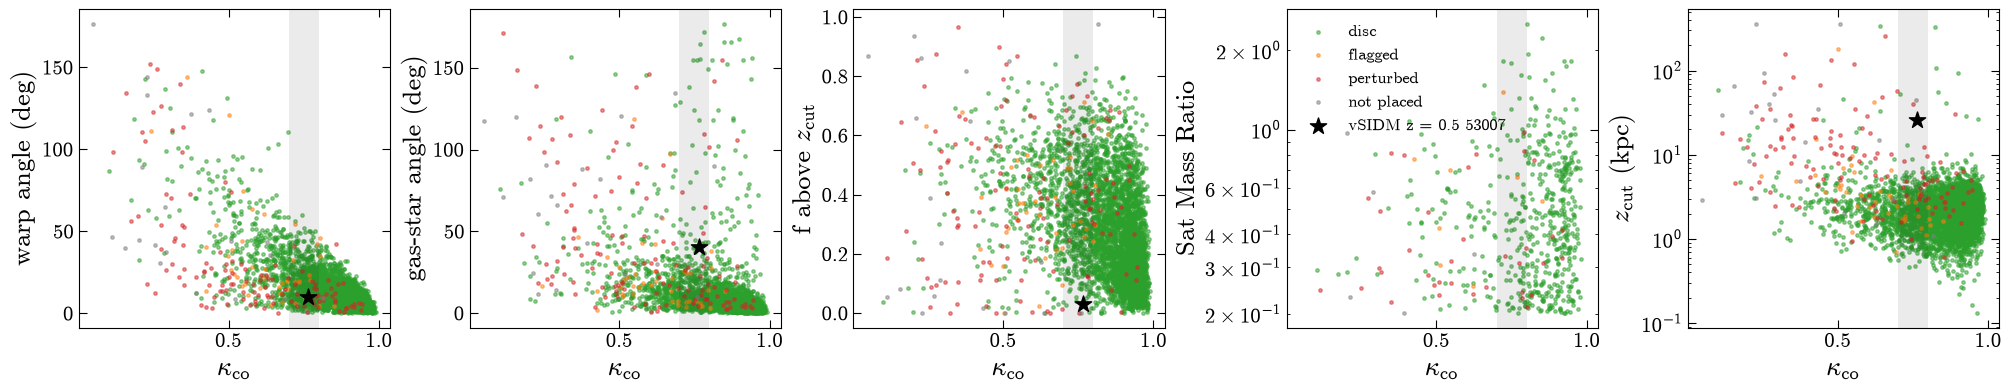

In [14]:
diag_q = ["warp_deg", "gas_star_deg", "f_above_zcut", "sat_mass_ratio", "z_cut"]
titles = ["warp angle (deg)", "gas-star angle (deg)", r"f above $z_{\rm cut}$", "Sat Mass Ratio", r"$z_{\rm cut}$ (kpc)"]
fig, axes = plt.subplots(1, len(diag_q), figsize=(4 * len(diag_q), 3.8), constrained_layout=True)
for ax, q in zip(axes, diag_q):
    for c, color in old_colors.items():
        g = df[df["old_class"] == c]
        ax.scatter(g["kappa_co_r99"], g[q], s=6, color=color, alpha=0.5, label=c)
    ax.axvspan(min(thresholds), max(thresholds), color="k", alpha=0.08, lw=0)
    for m, z, sub in watch:
        w = df[(df["model"] == m) & (df["z"] == z) & (df["subID"] == sub)]
        ax.scatter(w["kappa_co_r99"], w[q], s=150, marker="*", color="k", label=f"{m} z = {z:g} {sub}")
    if q in log_scale:
        ax.set_yscale("log", nonpositive="mask")
    ax.set_xlabel(r"$\kappa_{\rm co}$")
    ax.set_ylabel(titles[diag_q.index(q)])
axes[3].legend(fontsize=12, frameon=False)
plt.show()

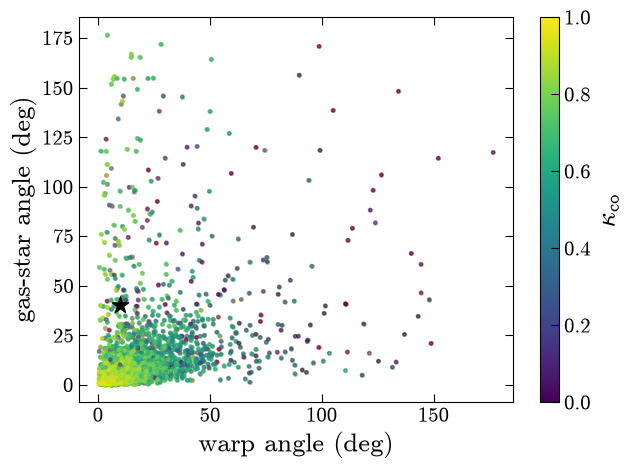

In [15]:
#plot gas star angle vs warp angle, color by kappa_co, mark the galaxies in watch
plt.figure(figsize=(7, 5))
for c, color in old_colors.items():
    g = df[df["old_class"] == c]
    plt.scatter(g["warp_deg"], g["gas_star_deg"], s=6, color=color, alpha=0.5, label=c)
plt.scatter(df["warp_deg"], df["gas_star_deg"], s=6, c=df["kappa_co_r95"], cmap="viridis", vmin=0.4, vmax=1, alpha=0.5)
ax.axvspan(min(thresholds), max(thresholds), color="k", alpha=0.08, lw=0)
for m, z, sub in watch:
    w = df[(df["model"] == m) & (df["z"] == z) & (df["subID"] == sub)]
    plt.scatter(w["warp_deg"], w["gas_star_deg"], s=150, marker="*", color="k", label=f"{m} z = {z:g} {sub}")
plt.xlabel("warp angle (deg)")
plt.ylabel("gas-star angle (deg)")
plt.colorbar(label=r"$\kappa_{\rm co}$")
plt.show()

In [16]:
LISTS.mkdir(parents=True, exist_ok=True)
disagree = {}
for t in thresholds:
    new = df[f"new_{t:g}"]
    disagree[(t, "only_old")] = df[df["old_disc"] & ~new].sort_values("kappa_co_r99")
    disagree[(t, "only_new")] = df[~df["old_disc"] & new].sort_values("kappa_co_r99", ascending=False)
for (t, name), d in disagree.items():
    f = LISTS / f"selection_{name}_kappa{t:g}.txt"
    f.write_text("".join(f"{r.model} {r.z:g} {r.subID} {name} kappa_co={r.kappa_co_r99:.2f} old={r.old_class}\n" for r in d.itertuples()))
    print(f"kappa_co >= {t:g}, {name}: {len(d)} galaxies -> {f}")

kappa_co >= 0.7, only_old: 433 galaxies -> /home2/s4636708/tmp/selection_only_old_kappa0.7.txt
kappa_co >= 0.7, only_new: 61 galaxies -> /home2/s4636708/tmp/selection_only_new_kappa0.7.txt
kappa_co >= 0.8, only_old: 987 galaxies -> /home2/s4636708/tmp/selection_only_old_kappa0.8.txt
kappa_co >= 0.8, only_new: 28 galaxies -> /home2/s4636708/tmp/selection_only_new_kappa0.8.txt


model   z  subID  kappa_co_r99 old_class     A_sq      mix
vSIDM 1.0  37199      0.102285      disc 0.619753 3.425373
SIDM1 0.5  87586      0.174384      disc 0.095362 3.084314
SIDM1 2.0  34495      0.184853      disc 0.183908 3.078103
vSIDM 1.0  24306      0.944926 perturbed 0.681382 3.992704
SIDM1 0.5  54942      0.942002 perturbed 0.645091 4.684543
vSIDM 0.5  62017      0.934517 perturbed 0.707375 3.928961


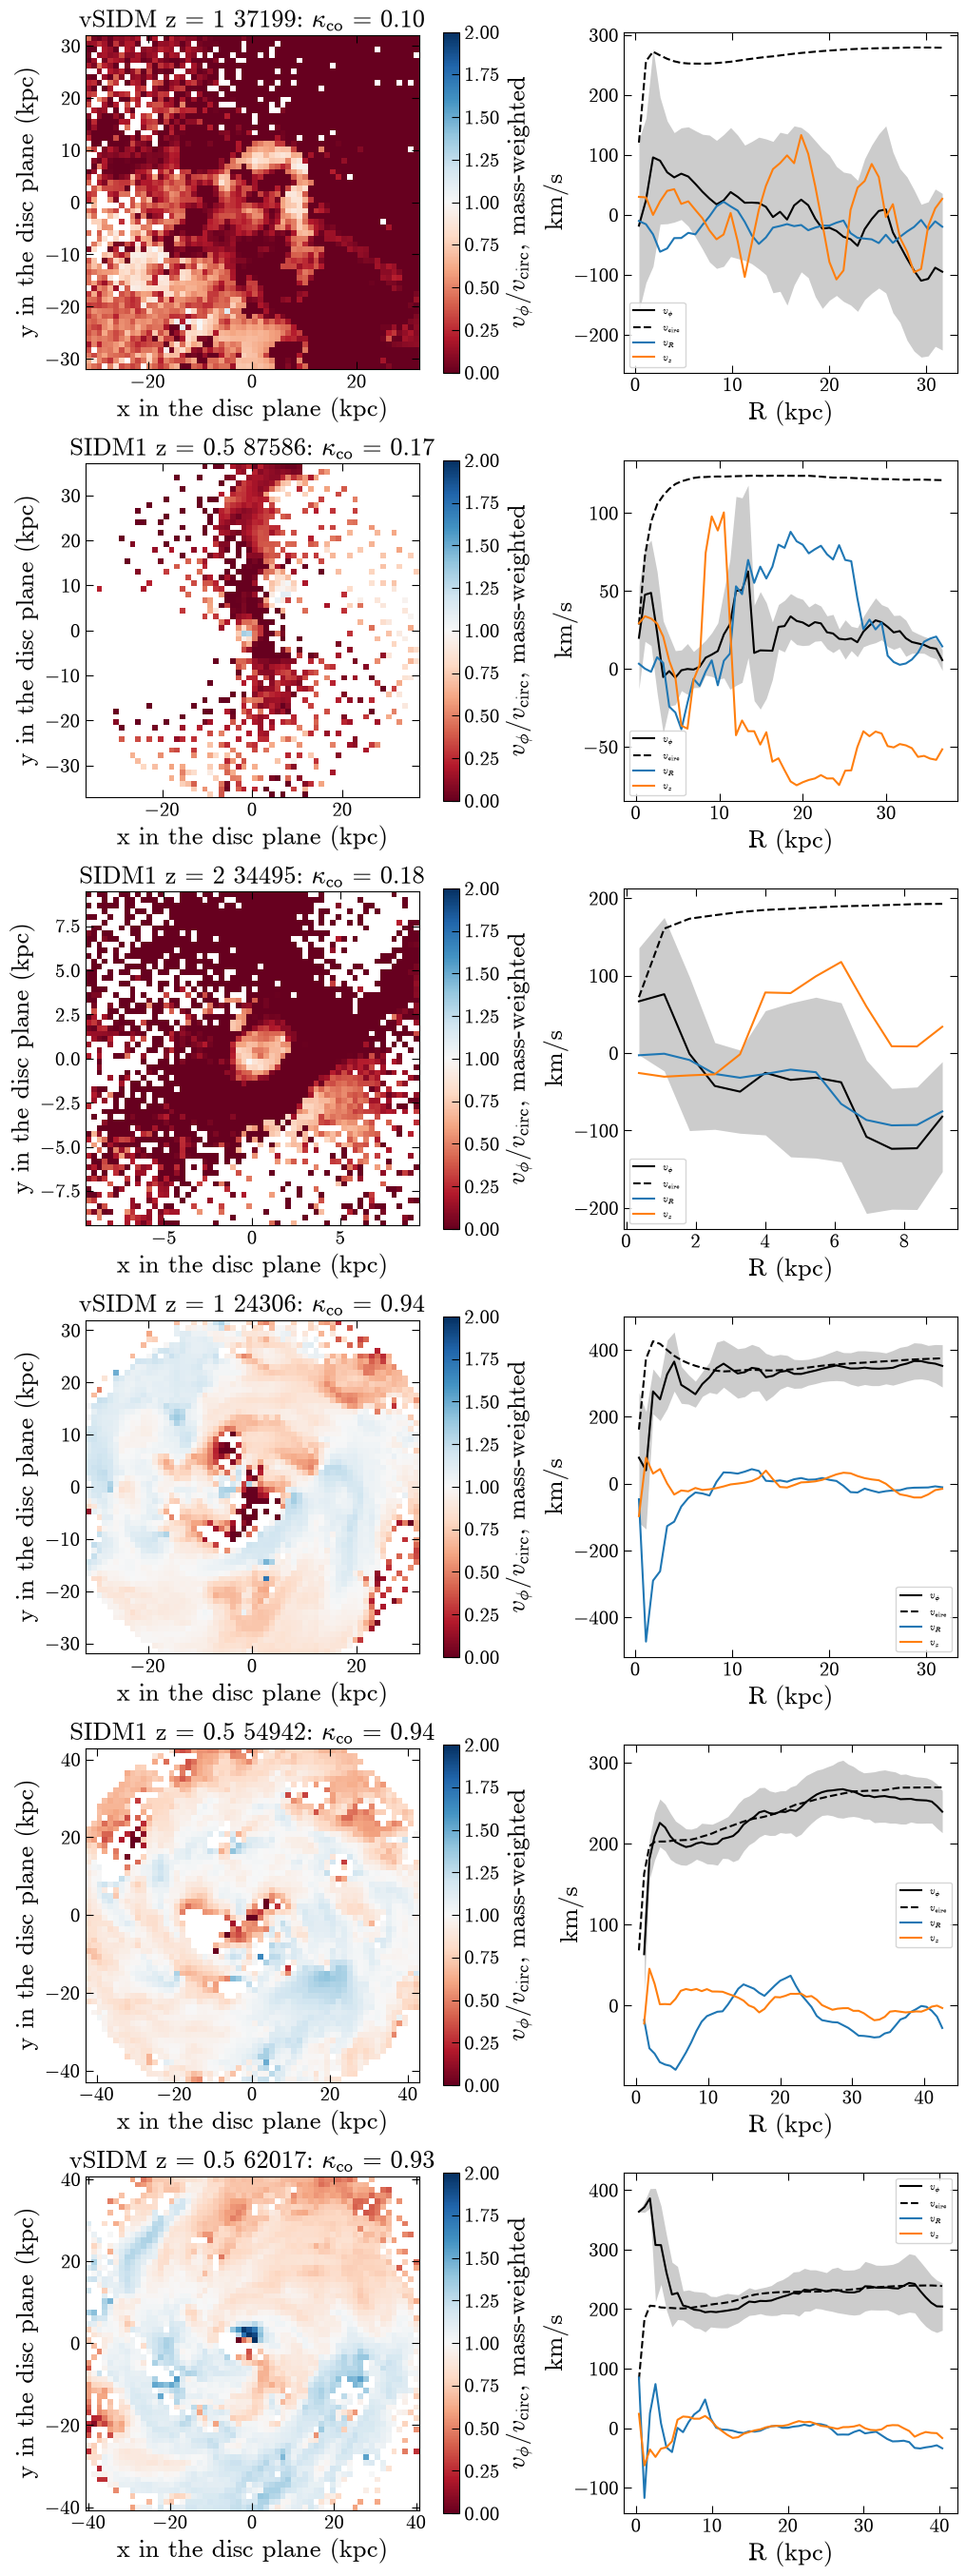

In [17]:
new = df["kappa_co_r99"] >= kappa_cut
strongest = pd.concat([df[df["old_disc"] & ~new].nsmallest(n_disagree, "kappa_co_r99"),
                       df[~df["old_disc"] & new].nlargest(n_disagree, "kappa_co_r99")])
print(strongest[["model", "z", "subID", "kappa_co_r99", "old_class", "A_sq", "mix"]].to_string(index=False))
plot_galaxies(list(zip(strongest["model"], strongest["z"], strongest["subID"])))

0 old discs have no R_rings in the gas-mass files, left out


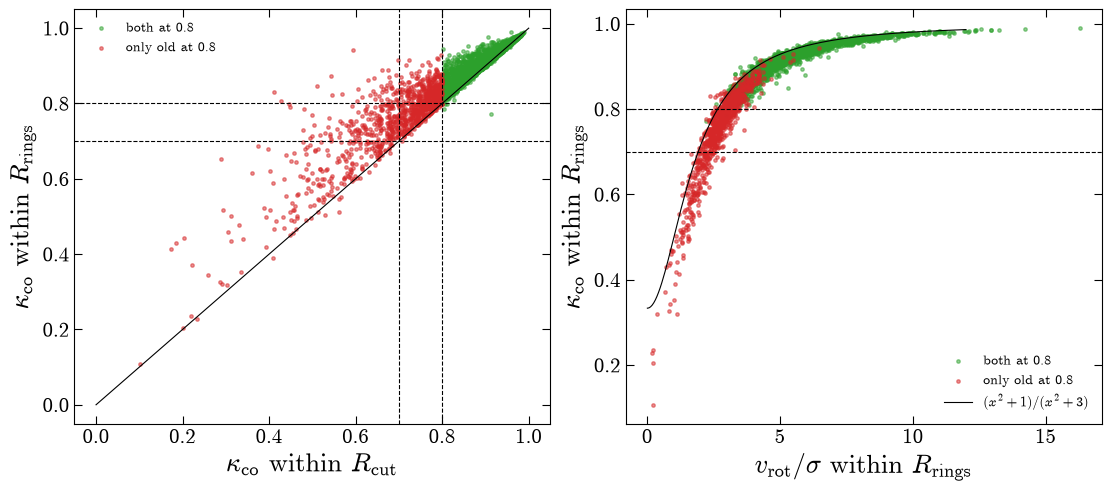

kappa_co >= 0.7: only-old galaxies per z {0.5: 86, 1.0: 101, 2.0: 135, 3.0: 85, 4.0: 24, 5.0: 2}; of them passing within R_rings {0.5: 35, 1.0: 41, 2.0: 84, 3.0: 50, 4.0: 14}
kappa_co >= 0.8: only-old galaxies per z {0.5: 176, 1.0: 252, 2.0: 300, 3.0: 201, 4.0: 52, 5.0: 6}; of them passing within R_rings {0.5: 57, 1.0: 80, 2.0: 125, 3.0: 64, 4.0: 18, 5.0: 1}


In [18]:
rings_kpc = {}
for (model, z), a in data.items():
    f = PROC / "gas_masses" / f"gas_masses_{model}_{a['snap']:03d}.hdf5"
    if f.exists():
        gm, _ = load_flat(f)
        rings_kpc.update({(model, z, int(s)): r for s, r in zip(gm["halo_ids"], gm["R_rings_kpc"])})
df["R_rings"] = [rings_kpc.get(k, np.nan) for k in zip(df["model"], df["z"], df["subID"])]
k_rings, vs_rings = [], []
with np.errstate(invalid="ignore", divide="ignore"):
    for model, z, sub, r_rings in zip(df["model"], df["z"], df["subID"], df["R_rings"]):
        a = data[(model, z)]
        i = np.flatnonzero(a["halo_ids"] == sub)[0]
        Rc = 0.5 * (a["ring_edges"][1:] + a["ring_edges"][:-1])
        inside = (Rc < r_rings) & (a["ring_mass"][i] > 0)
        m = a["ring_mass"][i][inside]
        sig2 = (a["ring_sigma_vR"][i] ** 2 + a["ring_sigma_vphi"][i] ** 2 + a["ring_sigma_vz"][i] ** 2)[inside] / 3
        k_rings.append(a["ring_K_co"][i][inside].sum() / a["ring_K"][i][inside].sum())
        vs_rings.append(m @ a["ring_vphi"][i][inside] / np.sqrt(m.sum() * (m @ sig2)))
df["kappa_co_rings"], df["vrot_sigma_rings"] = k_rings, vs_rings

old_discs = df[df["old_disc"] & df["R_rings"].notna()]
print(f"{int(df['old_disc'].sum()) - len(old_discs)} old discs have no R_rings in the gas-mass files, left out")
x = np.linspace(0, 12, 200)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), constrained_layout=True)
for passes, color, label in ((True, "tab:green", f"both at {kappa_cut:g}"), (False, "tab:red", f"only old at {kappa_cut:g}")):
    g = old_discs[(old_discs["kappa_co_r99"] >= kappa_cut) == passes]
    axes[0].scatter(g["kappa_co_r99"], g["kappa_co_rings"], s=6, color=color, alpha=0.5, label=label)
    axes[1].scatter(g["vrot_sigma_rings"], g["kappa_co_rings"], s=6, color=color, alpha=0.5, label=label)
axes[0].plot([0, 1], [0, 1], color="k", lw=0.8)
for t in thresholds:
    axes[0].axvline(t, color="k", ls="--", lw=0.8)
    axes[0].axhline(t, color="k", ls="--", lw=0.8)
    axes[1].axhline(t, color="k", ls="--", lw=0.8)
axes[1].plot(x, (x ** 2 + 1) / (x ** 2 + 3), color="k", lw=0.8, label=r"$(x^2+1)/(x^2+3)$")
axes[0].set_xlabel(r"$\kappa_{\rm co}$ within $R_{\rm cut}$")
axes[0].set_ylabel(r"$\kappa_{\rm co}$ within $R_{\rm rings}$")
axes[1].set_xlabel(r"$v_{\rm rot}/\sigma$ within $R_{\rm rings}$")
axes[1].set_ylabel(r"$\kappa_{\rm co}$ within $R_{\rm rings}$")
axes[0].legend(fontsize=10, frameon=False)
axes[1].legend(fontsize=10, frameon=False)
plt.show()
for t in thresholds:
    only_old = old_discs[old_discs["kappa_co_r99"] < t]
    passing = only_old[only_old["kappa_co_rings"] >= t]
    print(f"kappa_co >= {t:g}: only-old galaxies per z {only_old.groupby('z').size().to_dict()}; "
          f"of them passing within R_rings {passing.groupby('z').size().to_dict()}")

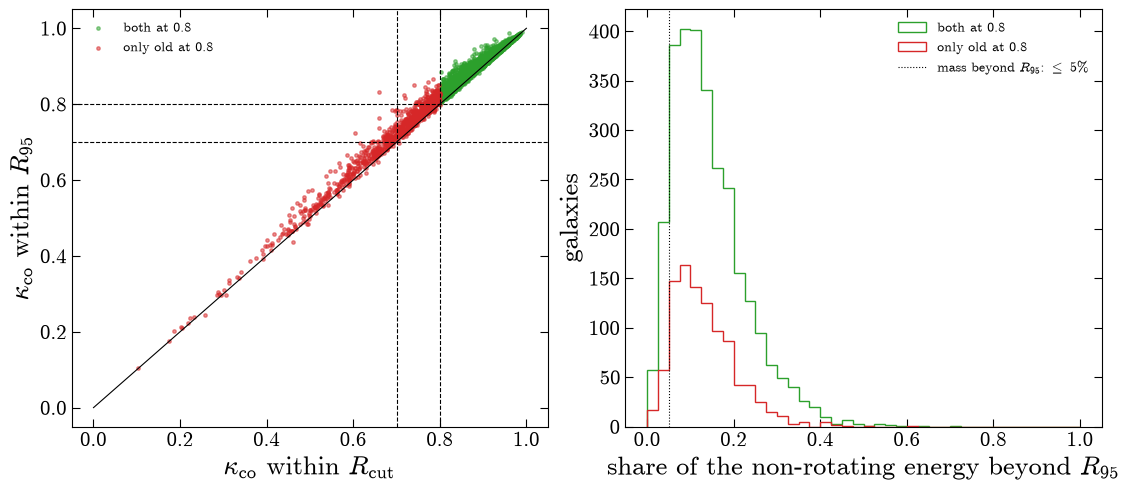

kappa_co >= 0.7: 433 only-old galaxies, 83 of them pass within R_95; median outer share: only old 0.10, both 0.13
kappa_co >= 0.8: 987 only-old galaxies, 170 of them pass within R_95; median outer share: only old 0.12, both 0.12


In [19]:
k95, out_share = [], []
with np.errstate(invalid="ignore", divide="ignore"):
    for model, z, sub in zip(df["model"], df["z"], df["subID"]):
        a = data[(model, z)]
        i = np.flatnonzero(a["halo_ids"] == sub)[0]
        mass, K, K_co = a["ring_mass"][i], a["ring_K"][i], a["ring_K_co"][i]
        n95 = np.searchsorted(np.cumsum(mass) / mass.sum(), 0.95) + 1
        k95.append(K_co[:n95].sum() / K[:n95].sum())
        out_share.append((K - K_co)[n95:].sum() / (K - K_co).sum())
df["kappa_co_95"], df["outer_share"] = k95, out_share

old_discs = df[df["old_disc"]]
bins = np.linspace(0, 1, 41)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), constrained_layout=True)
for passes, color, label in ((True, "tab:green", f"both at {kappa_cut:g}"), (False, "tab:red", f"only old at {kappa_cut:g}")):
    g = old_discs[(old_discs["kappa_co_r99"] >= kappa_cut) == passes]
    axes[0].scatter(g["kappa_co_r99"], g["kappa_co_95"], s=6, color=color, alpha=0.5, label=label)
    axes[1].hist(g["outer_share"], bins=bins, histtype="step", color=color, label=label)
axes[0].plot([0, 1], [0, 1], color="k", lw=0.8)
for t in thresholds:
    axes[0].axvline(t, color="k", ls="--", lw=0.8)
    axes[0].axhline(t, color="k", ls="--", lw=0.8)
axes[1].axvline(0.05, color="k", ls=":", lw=0.8, label=r"mass beyond $R_{95}$: $\leq$ 5%")
axes[0].set_xlabel(r"$\kappa_{\rm co}$ within $R_{\rm cut}$")
axes[0].set_ylabel(r"$\kappa_{\rm co}$ within $R_{95}$")
axes[1].set_xlabel(r"share of the non-rotating energy beyond $R_{95}$")
axes[1].set_ylabel("galaxies")
axes[0].legend(fontsize=10, frameon=False)
axes[1].legend(fontsize=10, frameon=False)
plt.show()
for t in thresholds:
    only_old, both = old_discs[old_discs["kappa_co_r99"] < t], old_discs[old_discs["kappa_co_r99"] >= t]
    print(f"kappa_co >= {t:g}: {len(only_old)} only-old galaxies, {int((only_old['kappa_co_95'] >= t).sum())} of them pass within R_95; "
          f"median outer share: only old {only_old['outer_share'].median():.2f}, both {both['outer_share'].median():.2f}")

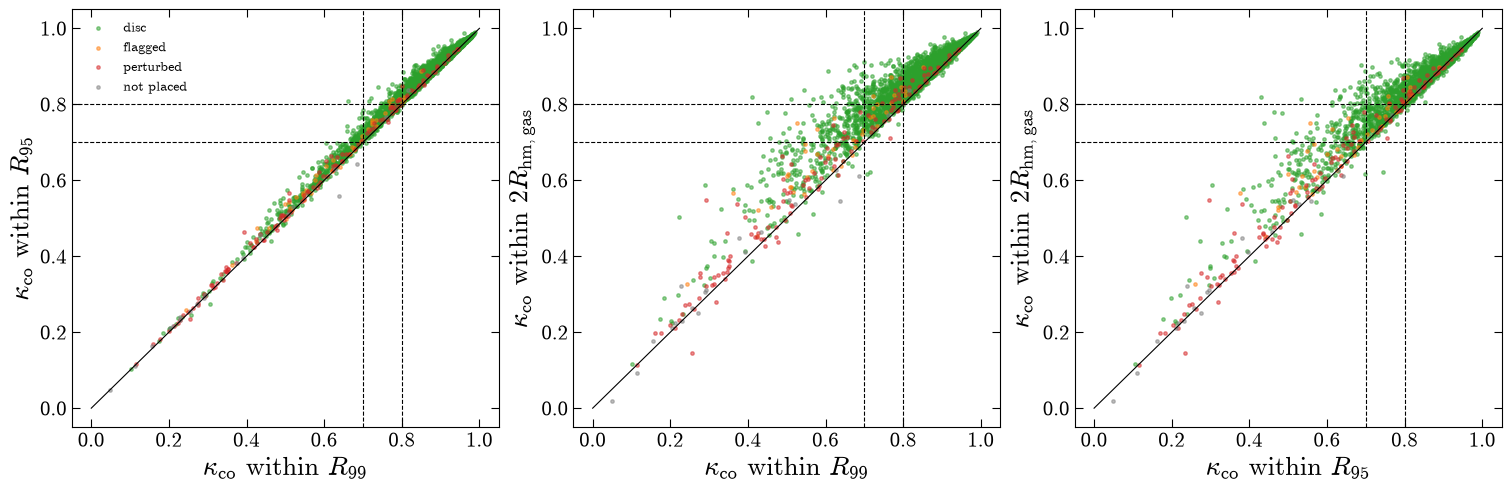

,z,kappa_min,galaxies,old_discs,pass kappa_co_r99,old discs passing kappa_co_r99,pass kappa_co_r95,old discs passing kappa_co_r95,pass kappa_co_2rhalf,old discs passing kappa_co_2rhalf
0,0.5,0.7,1424,1363,1303,1277,1311,1284,1339,1310
1,0.5,0.8,1424,1363,1202,1187,1224,1207,1257,1239
2,1.0,0.7,1339,1288,1201,1187,1215,1201,1246,1229
3,1.0,0.8,1339,1288,1043,1036,1076,1068,1143,1131
4,2.0,0.7,854,798,678,663,708,691,767,746
5,2.0,0.8,854,798,502,498,558,553,648,639
6,3.0,0.7,377,354,275,269,290,284,332,325
7,3.0,0.8,377,354,155,153,187,183,237,233
8,4.0,0.7,80,79,55,55,60,60,70,69
9,4.0,0.8,80,79,27,27,35,35,50,50


In [20]:
lookup = {(model, z, int(s)): i for (model, z), a in data.items() for i, s in enumerate(a["halo_ids"])}
kappas = {"kappa_co_r99": r"within $R_{99}$", "kappa_co_r95": r"within $R_{95}$", "kappa_co_2rhalf": r"within $2R_{\rm hm,gas}$"}
pairs = [("kappa_co_r99", "kappa_co_r95"), ("kappa_co_r99", "kappa_co_2rhalf"), ("kappa_co_r95", "kappa_co_2rhalf")]
fig, axes = plt.subplots(1, len(pairs), figsize=(5 * len(pairs), 4.8), constrained_layout=True)
for ax, (xk, yk) in zip(axes, pairs):
    for c, color in old_colors.items():
        g = df[df["old_class"] == c]
        ax.scatter(g[xk], g[yk], s=6, color=color, alpha=0.5, label=c)
    ax.plot([0, 1], [0, 1], color="k", lw=0.8)
    for t in thresholds:
        ax.axvline(t, color="k", ls="--", lw=0.8)
        ax.axhline(t, color="k", ls="--", lw=0.8)
    ax.set_xlabel(r"$\kappa_{\rm co}$ " + kappas[xk])
    ax.set_ylabel(r"$\kappa_{\rm co}$ " + kappas[yk])
axes[0].legend(fontsize=10, frameon=False)
plt.show()
rows = []
for z, g in df.groupby("z"):
    for t in thresholds:
        row = dict(z=z, kappa_min=t, galaxies=len(g), old_discs=int(g["old_disc"].sum()))
        for k in kappas:
            passes = g[k] >= t
            row[f"pass {k}"] = int(passes.sum())
            row[f"old discs passing {k}"] = int((passes & g["old_disc"]).sum())
        rows.append(row)
pd.DataFrame(rows)

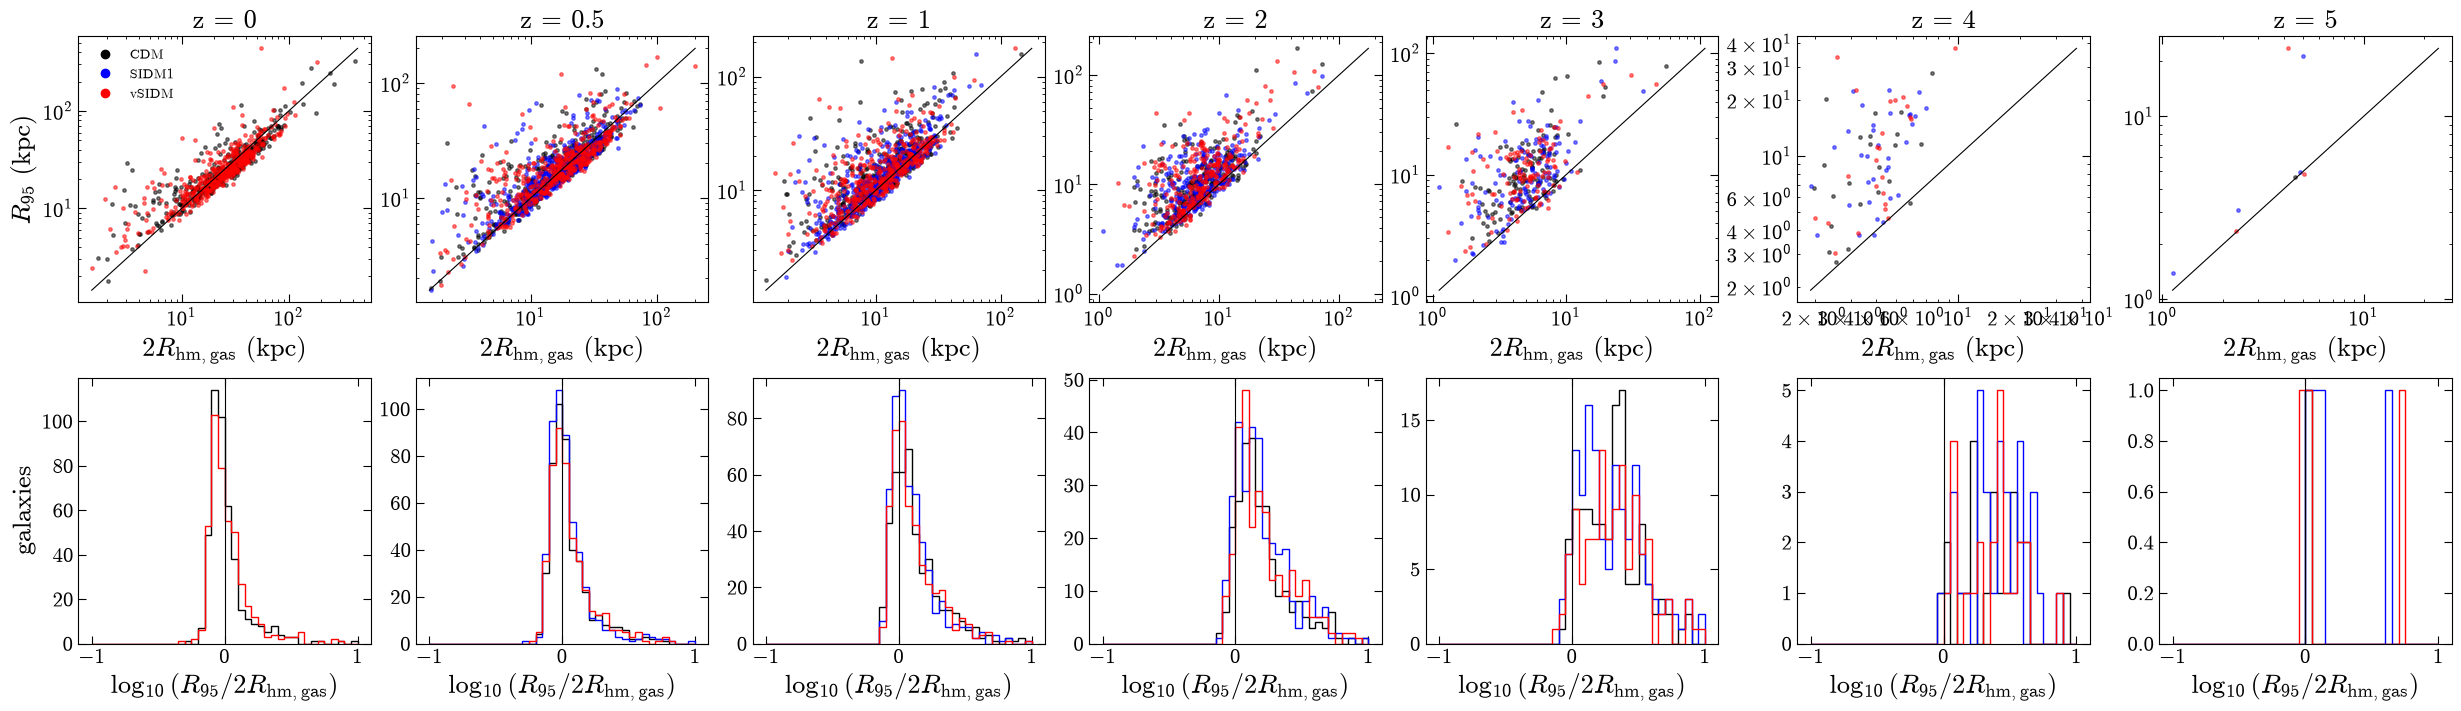

In [21]:
lbins = np.linspace(-1, 1, 41)
fig, axes = plt.subplots(2, len(redshifts), figsize=(3.5 * len(redshifts), 7), constrained_layout=True)
for col, z in zip(axes.T, redshifts):
    vals = []
    for model in MODELS:
        if (model, z) not in data:
            continue
        a = data[(model, z)]
        col[0].scatter(2 * a["R_half_gas"], a["R_95"], s=6, color=colors[model], alpha=0.5)
        col[1].hist(np.log10(a["R_95"] / (2 * a["R_half_gas"])), bins=lbins, histtype="step", color=colors[model])
        vals += [2 * a["R_half_gas"], a["R_95"]]
    vals = np.concatenate(vals)
    col[0].plot([vals.min(), vals.max()], [vals.min(), vals.max()], color="k", lw=0.8)
    col[0].set_xscale("log")
    col[0].set_yscale("log")
    col[0].set_title(f"z = {z:g}")
    col[0].set_xlabel(r"$2R_{\rm hm,gas}$ (kpc)")
    col[1].axvline(0, color="k", lw=0.8)
    col[1].set_xlabel(r"$\log_{10}(R_{95} / 2R_{\rm hm,gas})$")
axes[0, 0].set_ylabel(r"$R_{95}$ (kpc)")
axes[1, 0].set_ylabel("galaxies")
axes[0, 0].legend([Line2D([0], [0], marker="o", ls="none", color=colors[model]) for model in MODELS], MODELS,
                  fontsize=10, frameon=False)
plt.show()

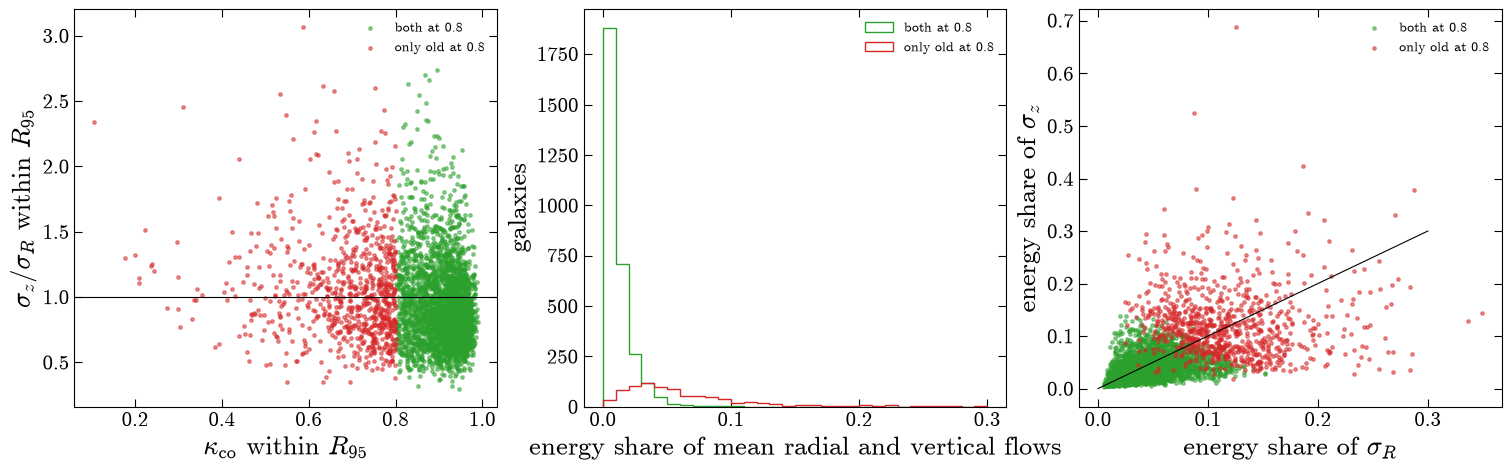

only old at 0.8: median sigma_z/sigma_R 1.01; median energy shares: flows 0.049, sigma_R 0.111, sigma_z 0.113
both at 0.8: median sigma_z/sigma_R 0.87; median energy shares: flows 0.007, sigma_R 0.039, sigma_z 0.030


In [22]:
share = {"flows": [], "sigma_R": [], "sigma_z": []}
ratio = []
with np.errstate(invalid="ignore", divide="ignore"):
    for model, z, sub, r95 in zip(df["model"], df["z"], df["subID"], df["R_95"]):
        a = data[(model, z)]
        i = lookup[(model, z, sub)]
        Rc = 0.5 * (a["ring_edges"][1:] + a["ring_edges"][:-1])
        s = (Rc < r95) & (a["ring_mass"][i] > 0)
        m, K = a["ring_mass"][i][s], a["ring_K"][i][s].sum()
        share["flows"].append(0.5 * m @ (a["ring_vR"][i][s] ** 2 + a["ring_vz"][i][s] ** 2) / K)
        share["sigma_R"].append(0.5 * m @ a["ring_sigma_vR"][i][s] ** 2 / K)
        share["sigma_z"].append(0.5 * m @ a["ring_sigma_vz"][i][s] ** 2 / K)
        ratio.append(np.sqrt((m @ a["ring_sigma_vz"][i][s] ** 2) / (m @ a["ring_sigma_vR"][i][s] ** 2)))
for k, v in share.items():
    df[f"share_{k}"] = v
df["sigz_sigR"] = ratio

old_discs = df[df["old_disc"]]
bins = np.linspace(0, 0.3, 31)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), constrained_layout=True)
for passes, color, label in ((True, "tab:green", f"both at {kappa_cut:g}"), (False, "tab:red", f"only old at {kappa_cut:g}")):
    g = old_discs[(old_discs["kappa_co_r95"] >= kappa_cut) == passes]
    axes[0].scatter(g["kappa_co_r95"], g["sigz_sigR"], s=6, color=color, alpha=0.5, label=label)
    axes[1].hist(g["share_flows"], bins=bins, histtype="step", color=color, label=label)
    axes[2].scatter(g["share_sigma_R"], g["share_sigma_z"], s=6, color=color, alpha=0.5, label=label)
axes[0].axhline(1, color="k", lw=0.8)
axes[2].plot([0, 0.3], [0, 0.3], color="k", lw=0.8)
axes[0].set_xlabel(r"$\kappa_{\rm co}$ within $R_{95}$")
axes[0].set_ylabel(r"$\sigma_z / \sigma_R$ within $R_{95}$")
axes[1].set_xlabel("energy share of mean radial and vertical flows")
axes[1].set_ylabel("galaxies")
axes[2].set_xlabel(r"energy share of $\sigma_R$")
axes[2].set_ylabel(r"energy share of $\sigma_z$")
for ax in axes:
    ax.legend(fontsize=10, frameon=False)
plt.show()
for passes, name in ((False, "only old"), (True, "both")):
    g = old_discs[(old_discs["kappa_co_r95"] >= kappa_cut) == passes]
    print(f"{name} at {kappa_cut:g}: median sigma_z/sigma_R {g['sigz_sigR'].median():.2f}; median energy shares: "
          f"flows {g['share_flows'].median():.3f}, sigma_R {g['share_sigma_R'].median():.3f}, sigma_z {g['share_sigma_z'].median():.3f}")

In [23]:
#print how many galaxies would be excluded with a cut on kappa_co_r95 > 0.7, 0.8, a cut on z_cut >= 10 kpc, a cut on gas-star angle > 30 deg, and a cut on warp angle > 30 deg
z_cut_max, angle_max = 10, 30
rows = []
for (model, z), a in sorted(data.items()):
    row = {"model": model, "z": z, "galaxies": len(a["halo_ids"])}
    thick, misaligned, warped = a["z_cut"] >= z_cut_max, a["gas_star_deg"] > angle_max, a["warp_deg"] > angle_max
    row.update({f"kappa_co_r95 < {t:g}": int((a["kappa_co_r95"] < t).sum()) for t in thresholds})
    row[f"z_cut >= {z_cut_max} kpc"] = int(thick.sum())
    row[f"gas-star > {angle_max} deg"] = int(misaligned.sum())
    row[f"warp > {angle_max} deg"] = int(warped.sum())
    row.update({f"total with kappa_co_r95 < {t:g}": int(((a["kappa_co_r95"] < t) | thick | misaligned | warped).sum())
                for t in thresholds})
    row["nan in any"] = int(sum(np.isnan(a[q]).sum() for q in ("kappa_co_r95", "z_cut", "gas_star_deg", "warp_deg")))
    rows.append(row)
excluded = pd.DataFrame(rows)
print("all:", excluded.drop(columns=["model", "z"]).sum().to_dict())
numeric = excluded.columns.drop(["model", "z"])
per_model = excluded.groupby("model")[numeric].sum().reset_index().assign(z="all")
total = excluded[numeric].sum().to_frame().T.assign(model="all", z="all")
excluded = pd.concat([excluded, per_model, total], ignore_index=True)
excluded

all: {'galaxies': 4963, 'kappa_co_r95 < 0.7': 559, 'kappa_co_r95 < 0.8': 1101, 'z_cut >= 10 kpc': 122, 'gas-star > 30 deg': 363, 'warp > 30 deg': 491, 'total with kappa_co_r95 < 0.7': 879, 'total with kappa_co_r95 < 0.8': 1259, 'nan in any': 2}


,model,z,galaxies,kappa_co_r95 < 0.7,kappa_co_r95 < 0.8,z_cut >= 10 kpc,gas-star > 30 deg,warp > 30 deg,total with kappa_co_r95 < 0.7,total with kappa_co_r95 < 0.8,nan in any
0,CDM,0.0,443,38,51,20,34,28,59,67,0
1,CDM,0.5,460,36,56,13,32,25,59,72,0
2,CDM,1.0,425,43,91,13,46,45,83,105,0
3,CDM,2.0,259,34,82,4,15,36,53,85,0
4,CDM,3.0,122,28,63,1,11,24,36,67,0
5,CDM,4.0,23,4,11,0,0,2,5,11,0
6,CDM,5.0,1,0,0,0,0,0,0,0,0
7,SIDM1,0.5,503,42,74,9,33,40,72,89,0
8,SIDM1,1.0,477,37,82,13,31,38,67,98,0
9,SIDM1,2.0,312,57,105,7,21,45,71,110,0


In [24]:
#percentage of galaxies cut off with a cut on warp angle > 30 deg, use df, in ONE line
print(100 * (df['warp_deg'] > 30).sum() / len(df), "%")

#percentage of galaxies cut off with a cut on gas-star angle > 30 deg, use df, in ONE line
print(100 * (df['gas_star_deg'] > angle_max).sum() / len(df), "%")

print(100 * (excluded[f"total with kappa_co_r95 < 0.8"].sum() / excluded["galaxies"].sum()), "%")

print(100 * (excluded[f"total with kappa_co_r95 < 0.7"].sum() / excluded["galaxies"].sum()), "%")

10.705536501714846 %
7.006369426751593 %
25.367721136409433 %
17.711061857747328 %


In [25]:
#gas-cut pilot: 50 galaxies at z = 0.5-5, discs in the current or the new selection, as a manifest for batch.sbatch
PILOT = PROC.parent / "martini_pilot_disc_cut"
seed, n_one_side, n_both = 1, 10, 26
hand_picked = [("CDM", 3.0, 19064), ("CDM", 3.0, 20669), ("CDM", 3.0, 9760), ("vSIDM", 0.5, 53007)]

rule_groups, rule = kinematic_sample(cfg, **DISC_RULE)
print("new selection:", rule)
in_rule = {(m, s, sub) for (m, s), subs in rule_groups.items() for sub in subs}
df["new_rule"] = [k in in_rule for k in zip(df["model"], df["snap"], df["subID"])]
missing = set(hand_picked) - set(zip(df["model"], df["z"], df["subID"]))
if missing:
    raise KeyError(f"not in df: {missing}")
is_hand_picked = np.array([k in set(hand_picked) for k in zip(df["model"], df["z"], df["subID"])])

rng = np.random.default_rng(seed)
pool = df[(df["old_disc"] | df["new_rule"]) & ~is_hand_picked]
current_only = pool[pool["old_disc"] & ~pool["new_rule"]].sample(n_one_side, random_state=rng)
new_only = pool[~pool["old_disc"] & pool["new_rule"]].sample(n_one_side, random_state=rng)
both = pool[pool["old_disc"] & pool["new_rule"]]
cell = 3 * pd.qcut(both["kappa_co_r95"], 3, labels=False) + pd.qcut(both["mix"], 3, labels=False)
quota = np.full(9, n_both // 9)
quota[rng.choice(9, n_both % 9, replace=False)] += 1
both = pd.concat([both[cell == c].sample(q, random_state=rng) for c, q in enumerate(quota)])
pilot = pd.concat([df[is_hand_picked].assign(group="hand-picked"), current_only.assign(group="current only"),
                   new_only.assign(group="new only"), both.assign(group="both")], ignore_index=True)

info_dir = PROC.parent / "martini"
pilot["cube_half_kpc"] = [json.loads((info_dir / f"z{z:g}" / m / f"gal_{s:06d}" / "info.json").read_text())["cube_half_kpc"]
                          for m, z, s in zip(pilot["model"], pilot["z"], pilot["subID"])]
(PILOT / "logs").mkdir(parents=True, exist_ok=True)
(PILOT / "manifest.txt").write_text("".join(f"{m} {s} {sub} {float(half)!r}\n" for m, s, sub, half
                                            in zip(pilot["model"], pilot["snap"], pilot["subID"], pilot["cube_half_kpc"])))
cols = ["group", "model", "z", "snap", "subID", "kappa_co_r95", "z_cut", "gas_star_deg", "warp_deg", "A_sq", "mix",
        "old_class", "old_disc", "new_rule", "cube_half_kpc"]
pilot[cols].to_csv(PILOT / "pilot.csv", index=False)
print(f"wrote {PILOT / 'manifest.txt'} and pilot.csv ({len(pilot)} galaxies)")
print("both, per (kappa_co_r95 third, mix third):", quota.reshape(3, 3).tolist())
print(pilot["group"].value_counts().to_dict())
print(pd.crosstab(pilot["model"], pilot["z"], margins=True))
pilot[cols]

new selection: kappa_co_r95 >= 0.8, z_cut < 10 kpc, gas-star and warp angles <= 30 deg of the neutral gas, MORDOR discs
wrote /scratch/s4636708/aida/derived/martini_pilot_disc_cut/manifest.txt and pilot.csv (50 galaxies)
both, per (kappa_co_r95 third, mix third): [[3, 3, 2], [3, 3, 3], [3, 3, 3]]
{'both': 26, 'old only': 10, 'new only': 10, 'looked at': 4}
z      0.5  1.0  2.0  3.0  4.0  All
model                              
CDM      5    2    2    5    0   14
SIDM1    6    4    6    1    1   18
vSIDM    9    5    4    0    0   18
All     20   11   12    6    1   50


,group,model,z,snap,subID,kappa_co_r95,z_cut,gas_star_deg,warp_deg,A_sq,mix,old_class,old_disc,new_rule,cube_half_kpc
0,looked at,CDM,3.0,25,19064,0.878540,0.844472,8.614704,10.681074,0.111555,2.543853,disc,True,True,8.000000
1,looked at,CDM,3.0,25,20669,0.894905,0.666822,6.477073,3.209854,0.123440,1.725828,disc,True,True,32.000000
2,looked at,CDM,3.0,25,9760,0.914843,0.654113,3.840239,2.774436,0.145317,2.654463,disc,True,True,8.000000
3,looked at,vSIDM,0.5,67,53007,0.753547,25.761252,40.404164,9.724972,1.001045,3.244777,perturbed,False,False,26.180000
4,old only,SIDM1,4.0,21,8086,0.692239,0.858343,7.250229,8.802185,0.108554,2.971261,disc,True,False,8.000000
5,old only,SIDM1,2.0,33,32680,0.532698,2.410117,21.122067,46.856416,0.336327,2.556961,disc,True,False,28.490000
6,old only,vSIDM,2.0,33,35226,0.771539,1.363497,11.106852,20.697497,0.064370,2.259346,disc,True,False,8.544841
7,old only,CDM,3.0,25,11195,0.794616,2.150576,10.776202,10.035309,0.216337,3.500468,disc,True,False,10.937499
8,old only,vSIDM,0.5,67,59176,0.796919,2.607766,10.137081,26.111581,0.223548,2.728592,disc,True,False,19.390000
9,old only,SIDM1,1.0,50,45275,0.767381,3.518438,123.882423,18.809731,0.420953,3.755238,disc,True,False,16.000000


In [3]:
#manifests for the full rebuild with the gas cut: z = 0.5-5 keep their current cube half-widths, z = 0 gets the cube-size rule
MARTINI = PROC.parent / "martini"
z_of_snap = {int(s): float(z) for s, z in cfg["snap_z"].items()}
has_cut = {(model, a["snap"], int(s)) for (model, z), a in data.items() for s in a["halo_ids"]}
lines, no_cut = {"z0.5-5": [], "z0": []}, []
for model, snap, sub in (l.split() for l in (MARTINI / "manifest.txt").read_text().splitlines() if l.strip()):
    snap, sub = int(snap), int(sub)
    z = z_of_snap[snap]
    if (model, snap, sub) not in has_cut:
        no_cut.append(f"{model} z = {z:g} {sub}")
    elif z == 0:
        lines["z0"].append(f"{model} {snap} {sub}")
    else:
        info = json.loads((MARTINI / f"z{z:g}" / model / f"gal_{sub:06d}" / "info.json").read_text())
        lines["z0.5-5"].append(f"{model} {snap} {sub} {float(info['cube_half_kpc'])!r}")
print("left out, no gas cut:", no_cut)
runs = {"z0.5-5": (10, "GROW_FOV= STAGES=cube,barolo_3rings,barolo,kinematics"),
        "z0": (5, "GROW_FOV=1 STAGES=sphview,cube,barolo_3rings,barolo,kinematics")}
for name, (chunk, settings) in runs.items():
    out = MARTINI / f"manifest_disc_cut_{name}.txt"
    out.write_text("".join(l + "\n" for l in lines[name]))
    print(f"\nwrote {out} ({len(lines[name])} galaxies); submit from ~/master_thesis_project:")
    print(f"NUMPY_MADVISE_HUGEPAGE=0 MANIFEST={out} DISC_CUT=1 CHUNK={chunk} {settings} sbatch --export=ALL "
          f"--array=0-{-(-len(lines[name]) // chunk) - 1}%100 --mem=64G --time=08:00:00 scripts/mock/batch.sbatch")

left out, no gas cut: ['vSIDM z = 0 122751', 'vSIDM z = 0 129790']

wrote /scratch/s4636708/aida/derived/martini/manifest_disc_cut_z0.5-5.txt (4082 galaxies); submit from ~/master_thesis_project:
NUMPY_MADVISE_HUGEPAGE=0 MANIFEST=/scratch/s4636708/aida/derived/martini/manifest_disc_cut_z0.5-5.txt DISC_CUT=1 CHUNK=10 GROW_FOV= STAGES=cube,barolo_3rings,barolo,kinematics sbatch --export=ALL --array=0-408%100 --mem=64G --time=08:00:00 scripts/mock/batch.sbatch

wrote /scratch/s4636708/aida/derived/martini/manifest_disc_cut_z0.txt (881 galaxies); submit from ~/master_thesis_project:
NUMPY_MADVISE_HUGEPAGE=0 MANIFEST=/scratch/s4636708/aida/derived/martini/manifest_disc_cut_z0.txt DISC_CUT=1 CHUNK=5 GROW_FOV=1 STAGES=sphview,cube,barolo_3rings,barolo,kinematics sbatch --export=ALL --array=0-176%100 --mem=64G --time=08:00:00 scripts/mock/batch.sbatch
